## 1. Setup and pinned data download
The dataset (`martj42/international_results`, CC0) is pinned to one commit and SHA-256 checked, so every number below is reproducible.

In [1]:
import hashlib, json, time, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar      # optimisers only; no model is imported
from IPython.display import display

SEED = 42
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

def check(tests: dict, label: str):
    """Print every named test, then stop the notebook if any failed."""
    for name, ok in tests.items():
        print(f"[{'PASS' if ok else 'FAIL'}] {name}")
    assert all(tests.values()), f"{label} failed"

COMMIT = "394fe81893b062fbc2cf6257e988ac7cc4c039a1"      # repository state on 2026-08-27
FILES = {"results.csv":   "df35268f8fc341ff7fb93d448b4e40356676ac35300a6b4461fd199a99ac1514",
         "shootouts.csv": "2acdc95fdad14f5f17200150a1a4a5fa6c2ccf57d31c8b4f61a2c7d9c0493113"}

def fetch(name, sha):
    path = Path("data") / name
    path.parent.mkdir(exist_ok=True)
    if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != sha:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/martj42/international_results/{COMMIT}/{name}", path)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == sha, f"{name}: hash mismatch, data changed"
    return pd.read_csv(path, parse_dates=["date"])

results, shootouts = (fetch(n, s) for n, s in FILES.items())
assert list(results.columns) == ["date", "home_team", "away_team", "home_score", "away_score",
                                 "tournament", "city", "country", "neutral"]
assert results["neutral"].dtype == bool
print(f"results.csv: {len(results):,} matches, {results['date'].min().date()} to {results['date'].max().date()}")

results.csv: 49,547 matches, 1872-11-30 to 2026-08-26


## 2. Study periods and label
Label: `y = 0` A win, `1` draw, `2` B win, from the score **including extra time, excluding shootouts** (a shootout is a draw).

In [2]:
PERIODS = {"burn_in": "1872-01-01", "train": "1994-01-01", "validation": "2015-01-01",
           "test": "2019-01-01", "wc2026_window": "2026-06-11"}
STUDY_END = pd.Timestamp("2026-07-20")                    # day after the 2026 World Cup final
PERIOD_LABELS = list(PERIODS)
OUTCOMES = ["home_win", "draw", "away_win"]

def assign_period(dates):
    edges = [pd.Timestamp(d) for d in PERIODS.values()] + [STUDY_END]
    return pd.cut(dates, edges, labels=PERIOD_LABELS, right=False).astype(object).fillna("outside_study")

def outcome(home_score, away_score):
    h, a = np.asarray(home_score), np.asarray(away_score)
    return np.select([h > a, h == a], [0, 1], default=2)

results["period"] = assign_period(results["date"])
results["y"] = outcome(results["home_score"], results["away_score"])

## 3. Data preprocessing 

,value
matches,"49,547"
distinct teams / tournaments,337 / 202
missing values in results.csv,0
rows sorted by date,True
team-dates with 2+ matches (no kickoff times),139
neutral rows where a team is the host country,0
shootouts recorded (never used as a feature),683


y,home_win,draw,away_win,matches
period,,,,
burn_in,0.498,0.219,0.284,19503
train,0.490,0.235,0.276,18914
validation,0.475,0.236,0.290,3812
test,0.479,0.228,0.293,7187
wc2026_window,0.476,0.229,0.295,105
outside_study,0.385,0.115,0.500,26


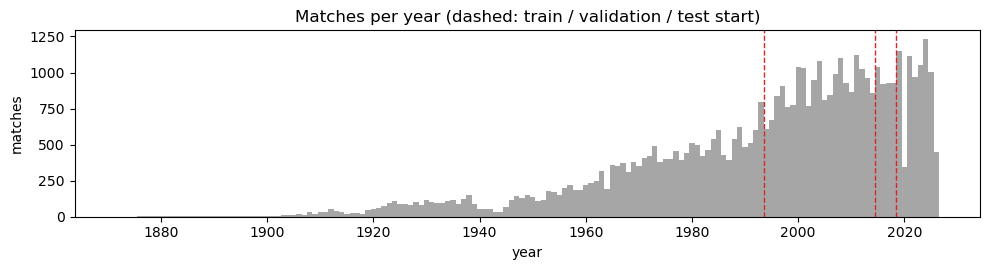

In [3]:
teams = pd.concat([results["home_team"], results["away_team"]])
long = pd.DataFrame({"date": pd.concat([results["date"]] * 2), "team": teams})
same_day_clashes = long.duplicated(["date", "team"], keep=False)

audit = pd.Series({
    "matches": f"{len(results):,}",
    "distinct teams / tournaments": f"{teams.nunique()} / {results['tournament'].nunique()}",
    "missing values in results.csv": int(results.isna().sum().sum()),
    "rows sorted by date": results["date"].is_monotonic_increasing,
    "team-dates with 2+ matches (no kickoff times)": int(long[same_day_clashes].drop_duplicates().shape[0]),
    "neutral rows where a team is the host country": int(((results["home_team"] == results["country"])
                                                          | (results["away_team"] == results["country"]))[results["neutral"]].sum()),
    "shootouts recorded (never used as a feature)": len(shootouts),
}, name="value").to_frame()
display(audit)

by_period = pd.crosstab(results["period"], results["y"].map(dict(enumerate(OUTCOMES))), normalize="index")
by_period = by_period[OUTCOMES].round(3).assign(matches=results["period"].value_counts()).reindex(PERIOD_LABELS + ["outside_study"])
display(by_period)

per_year = results.groupby(results["date"].dt.year).size()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(per_year.index, per_year.values, width=1, color="0.65")
for name in ["train", "validation", "test"]:
    ax.axvline(pd.Timestamp(PERIODS[name]).year - 0.5, color="C3", ls="--", lw=1)
ax.set(title="Matches per year (dashed: train / validation / test start)", xlabel="year", ylabel="matches")
plt.tight_layout(); plt.show()

draws are ~23% of matches, so the model must predict a 3-way outcome, not win/loss.
Many teams play twice on one date with no kickoff time, so every feature must use the state **at the start of the day** (rule A6).
Rows after 2026-07-20 are outside the study.

In [4]:
TOURNAMENT_ALIASES = {"AFF Championship": "ASEAN Championship",
                      "AFF Championship qualification": "ASEAN Championship qualification",
                      "CONIFA World Cup qualification": "CONIFA World Football Cup qualification"}

def rows_to_drop(r):
    """D2: duplicates entered twice, possibly with home/away swapped."""
    first = r["home_team"] < r["away_team"]                         # orient each pair alphabetically
    hs, as_ = r["home_score"].astype(str), r["away_score"].astype(str)
    d = pd.DataFrame({"date": r["date"],
                      "t1": r["home_team"].where(first, r["away_team"]),
                      "t2": r["away_team"].where(first, r["home_team"]),
                      "score": (hs + "-" + as_).where(first, as_ + "-" + hs),
                      "city": r["city"], "friendly": r["tournament"].eq("Friendly")})
    d = d[d.duplicated(["date", "t1", "t2"], keep=False)]
    drop = []
    for _, g in d.groupby(["date", "t1", "t2"]):
        if g["city"].nunique() > 1:                                # different cities: keep all
            continue
        if g["score"].nunique() > 1:                               # contradictory records: drop all
            drop += list(g.index)
        else:                                                      # same match twice: keep one
            drop += list(g.sort_values("friendly", kind="stable").index[1:])
    return sorted(drop)

def assign_tier(tournament):
    t = tournament.astype(str)
    return np.select([t.eq("Friendly"), t.str.endswith("qualification")], ["friendly", "qualifier"], "finals")

DROP_ROWS = rows_to_drop(results)
matches = (results.drop(index=DROP_ROWS)
           .loc[lambda d: d["date"] < STUDY_END,
                ["date", "home_team", "away_team", "home_score", "away_score", "tournament", "neutral", "y", "period"]]
           .rename_axis("match_id").reset_index())
matches["tournament"] = matches["tournament"].replace(TOURNAMENT_ALIASES)
matches["tier"] = assign_tier(matches["tournament"])

check({"sorted by date": matches["date"].is_monotonic_increasing,
       "no missing values": not matches.isna().any().any(),
       "every row in a study period": matches["period"].isin(PERIOD_LABELS).all(),
       "WC-2026 window holds the 104 World Cup matches":
           ((matches["period"] == "wc2026_window") & (matches["tournament"] == "FIFA World Cup")).sum() == 104},
      "cleaning")
print(f"Dropped {len(DROP_ROWS)} duplicate rows (all pre-1994). Working table: {len(matches):,} matches")
display(matches["period"].value_counts().reindex(PERIOD_LABELS).to_frame("matches"))

[PASS] sorted by date
[PASS] no missing values
[PASS] every row in a study period
[PASS] WC-2026 window holds the 104 World Cup matches
Dropped 5 duplicate rows (all pre-1994). Working table: 49,516 matches


,matches
period,
burn_in,19498
train,18914
validation,3812
test,7187
wc2026_window,105


## 4. Elo ratings

In [5]:
ELO_INITIAL, K_GRID = 1500.0, [10, 20, 30, 40]

def expected_score(r_a, r_b):
    return 1.0 / (1.0 + 10.0 ** ((r_b - r_a) / 400.0))

def update_elo(r_a, r_b, s_a, k):
    delta = k * (s_a - expected_score(r_a, r_b))
    return r_a + delta, r_b - delta

def elo_pass(m, k):
    """One chronological Elo pass. Returns one row per match: pre-match features + post-match diagnostics."""
    ratings, pending, rows = {}, {}, []
    prev_date = None
    for mid, date, a, b, y in zip(m["match_id"], m["date"], m["home_team"], m["away_team"], m["y"]):
        if date != prev_date:                                  # a new day: apply yesterday's updates (A6)
            for t, d in pending.items():
                ratings[t] += d
            pending, prev_date = {}, date
        r_a, r_b = ratings.setdefault(a, ELO_INITIAL), ratings.setdefault(b, ELO_INITIAL)
        e_a = expected_score(r_a, r_b)                         # features frozen here ...
        s_a = 1 - y / 2                                        # ... and only now is the result read
        new_a, _ = update_elo(r_a, r_b, s_a, k)
        pending[a] = pending.get(a, 0.0) + (new_a - r_a)
        pending[b] = pending.get(b, 0.0) - (new_a - r_a)
        rows.append((mid, r_a, r_b, e_a, s_a, new_a, r_b - (new_a - r_a)))
    for t, d in pending.items():
        ratings[t] += d
    out = pd.DataFrame(rows, columns=["match_id", "elo_a_pre", "elo_b_pre", "elo_expected_a", "score_a",
                                      "post_elo_a", "post_elo_b"]).set_index("match_id")
    out["elo_diff"] = out["elo_a_pre"] - out["elo_b_pre"]
    return out, pd.Series(ratings).sort_values(ascending=False)

check({"equal ratings give E_A = 0.5": np.isclose(expected_score(1500, 1500), 0.5),
       "E_A + E_B = 1": np.isclose(expected_score(1720, 1455) + expected_score(1455, 1720), 1),
       "400-point edge gives 10/11": np.isclose(expected_score(1900, 1500), 10 / 11),
       "equal teams, A wins: +K/2": np.allclose(update_elo(1500, 1500, 1, 20), (1510, 1490)),
       "update is zero-sum": np.isclose(sum(update_elo(1732, 1408, 0, 30)), 1732 + 1408)}, "Elo unit tests")

t0 = time.perf_counter()
ELO = {k: elo_pass(matches, k) for k in K_GRID}                # k -> (features, final ratings)
print(f"{len(K_GRID)} Elo passes in {time.perf_counter() - t0:.1f}s")
display(pd.DataFrame({f"K = {k}": ELO[k][1].head(10).index for k in K_GRID}, index=range(1, 11)))

[PASS] equal ratings give E_A = 0.5
[PASS] E_A + E_B = 1
[PASS] 400-point edge gives 10/11
[PASS] equal teams, A wins: +K/2
[PASS] update is zero-sum
4 Elo passes in 1.1s


,K = 10,K = 20,K = 30,K = 40
1,Spain,Spain,Spain,Spain
2,Argentina,Argentina,Argentina,Argentina
3,France,France,France,France
4,Brazil,England,England,England
5,England,Brazil,Portugal,Portugal
6,Portugal,Portugal,Brazil,Colombia
7,Germany,Colombia,Colombia,Brazil
8,Netherlands,Netherlands,Netherlands,Germany
9,Colombia,Germany,Germany,Netherlands
10,Belgium,Morocco,Morocco,Morocco


### 4.1 K experiment (train and validation)

In [6]:
def calibration(e, s, n_bins=10, min_bin=50):
    idx = np.clip(np.digitize(e, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    t = pd.DataFrame({"bin": idx, "e": e, "s": s}).groupby("bin").agg(e=("e", "mean"), s=("s", "mean"), n=("e", "size"))
    return t[t["n"] >= min_bin]

rows = []
for k in K_GRID:
    f = ELO[k][0].join(matches.set_index("match_id")["period"])
    for p in ["train", "validation"]:
        g = f[f["period"] == p]
        e, s = g["elo_expected_a"].to_numpy(), g["score_a"].to_numpy()
        dec = s != 0.5
        cal = calibration(e, s)
        rows.append({"K": k, "period": p,
                     "log_loss_decisive": -np.mean(s[dec] * np.log(e[dec]) + (1 - s[dec]) * np.log(1 - e[dec])),
                     "accuracy_decisive": np.mean((e[dec] > 0.5) == (s[dec] == 1)),
                     "brier_all": np.mean((e - s) ** 2),
                     "ece": (cal["n"] * (cal["e"] - cal["s"]).abs()).sum() / len(g)})
ELO_K_RESULTS = pd.DataFrame(rows).set_index(["period", "K"]).sort_index()
display(ELO_K_RESULTS.round(4))

log_loss_decisive  accuracy_decisive  brier_all     ece
period     K                                                          
train      10             0.5732             0.7100     0.1539  0.0970
           20             0.5508             0.7254     0.1488  0.0937
           30             0.5410             0.7291     0.1471  0.0916
           40             0.5363             0.7287     0.1467  0.0905
validation 10             0.5591             0.7279     0.1493  0.0776
           20             0.5363             0.7358     0.1441  0.0750
           30             0.5263             0.7443     0.1424  0.0738
           40             0.5214             0.7461     0.1421  0.0731

### 4.2 Elo leakage tests
**Prefix invariance** is the key test: re-run Elo on only the rows before 2015. If any later match influenced an earlier feature, the two runs would differ.

In [7]:
feats20, final20 = ELO[20]
cut = int((matches["date"] < "2015-01-01").sum())
prefix = elo_pass(matches.iloc[:cut], 20)[0]
check({f"prefix invariance ({cut:,} rows re-run without any later match)":
           np.allclose(prefix[["elo_a_pre", "elo_b_pre"]], feats20.iloc[:cut][["elo_a_pre", "elo_b_pre"]]),
       "zero-sum: mean final rating = 1500 for every K": all(abs(ELO[k][1].mean() - ELO_INITIAL) < 1e-8 for k in K_GRID),
       "debutants enter at 1500": feats20["elo_a_pre"].iloc[0] == ELO_INITIAL,
       "E_A consistent with elo_diff": np.allclose(feats20["elo_expected_a"], expected_score(feats20["elo_diff"], 0))},
      "Elo leakage tests")

[PASS] prefix invariance (38,412 rows re-run without any later match)
[PASS] zero-sum: mean final rating = 1500 for every K
[PASS] debutants enter at 1500
[PASS] E_A consistent with elo_diff


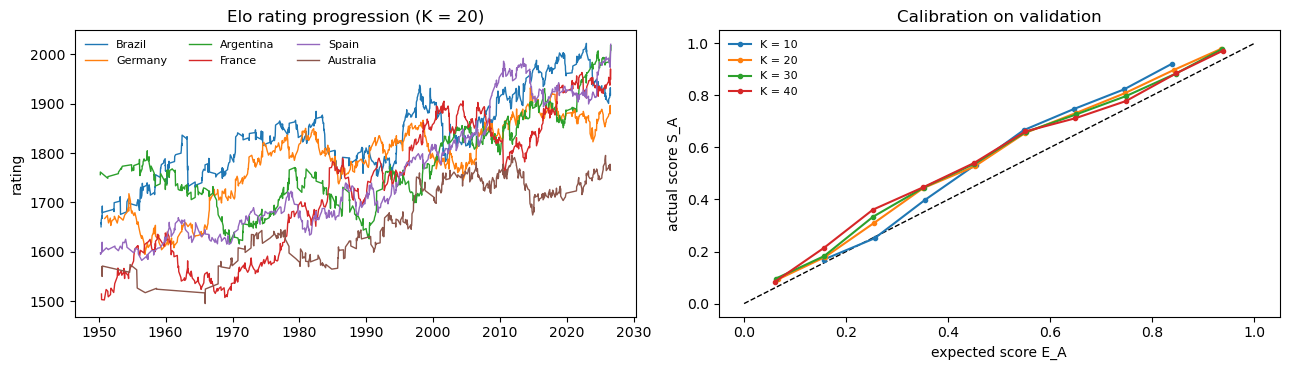

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
hist = pd.concat([pd.DataFrame({"team": matches["home_team"], "date": matches["date"], "r": feats20["post_elo_a"].to_numpy()}),
                  pd.DataFrame({"team": matches["away_team"], "date": matches["date"], "r": feats20["post_elo_b"].to_numpy()})])
for team in ["Brazil", "Germany", "Argentina", "France", "Spain", "Australia"]:
    h = hist[(hist["team"] == team) & (hist["date"] >= "1950")].sort_values("date", kind="stable")
    axes[0].plot(h["date"], h["r"], lw=1, label=team)
axes[0].set(title="Elo rating progression (K = 20)", ylabel="rating"); axes[0].legend(ncol=3, fontsize=8, frameon=False)

axes[1].plot([0, 1], [0, 1], "k--", lw=1)
val = matches["period"].eq("validation").to_numpy()
for k in K_GRID:
    c = calibration(ELO[k][0]["elo_expected_a"].to_numpy()[val], ELO[k][0]["score_a"].to_numpy()[val])
    axes[1].plot(c["e"], c["s"], "o-", ms=3, label=f"K = {k}")
axes[1].set(title="Calibration on validation", xlabel="expected score E_A", ylabel="actual score S_A")
axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()


## 6. Form features

In [9]:
GOAL_CAP, SHRINK_M, FORM_WINDOWS = 6, 2.0, [5, 10, 20]
STATS = ["win", "draw", "gf_c", "ga_c", "surprise"]

def team_log(m, elo):
    """One row per (match, team), from that team's view. POST-MATCH record: never a feature table itself."""
    exp_home = elo.loc[m["match_id"], "elo_expected_a"].to_numpy()
    sides = []
    for side, opp, exp in [("home", "away", exp_home), ("away", "home", 1 - exp_home)]:
        gf, ga = m[f"{side}_score"].to_numpy(float), m[f"{opp}_score"].to_numpy(float)
        score = np.select([gf > ga, gf == ga], [1.0, 0.5], 0.0)
        sides.append(pd.DataFrame({"match_id": m["match_id"].to_numpy(), "date": m["date"].to_numpy(),
                                   "team": m[f"{side}_team"].to_numpy(), "side": side,
                                   "win": (gf > ga).astype(float), "draw": (gf == ga).astype(float),
                                   "gf_c": np.minimum(gf, GOAL_CAP), "ga_c": np.minimum(ga, GOAL_CAP),
                                   "surprise": score - exp}))           # realised minus Elo-expected score
    return pd.concat(sides, ignore_index=True).sort_values(["team", "date", "match_id"], kind="stable", ignore_index=True)

def rolling_prior(log, w):
    """Mean of each stat over the team's previous w matches with a STRICTLY EARLIER date."""
    out = {c: np.full(len(log), np.nan) for c in STATS + ["span"]}
    out["n_used"], out["n_prior"] = np.zeros(len(log)), np.zeros(len(log))
    day = (log["date"] - pd.Timestamp("1800-01-01")).dt.days.to_numpy(float)
    for idx in log.groupby("team", sort=False).indices.values():
        d = day[idx]
        e = np.searchsorted(d, d, side="left")                 # matches strictly before this date
        lo = np.maximum(e - w, 0)
        n = e - lo
        ok = n > 0
        out["n_used"][idx], out["n_prior"][idx] = n, e
        out["span"][idx[ok]] = d[ok] - d[lo[ok]]                # calendar days the window covers
        for c in STATS:
            cs = np.concatenate([[0.0], np.cumsum(log[c].to_numpy(float)[idx])])
            out[c][idx[ok]] = (cs[e] - cs[lo])[ok] / n[ok]
    return pd.DataFrame(out, index=log.index)

def shrink(mean, n, prior, m=SHRINK_M):
    return (mean.fillna(0.0) * n + m * prior) / (n + m)

# Shrinkage priors: TRAIN rows only; surprise is exactly 0 because the Elo update is zero-sum.
_log20 = team_log(matches, feats20)
_train_ids = matches.loc[matches["period"] == "train", "match_id"]
PRIORS = _log20[_log20["match_id"].isin(_train_ids)][["win", "draw", "gf_c", "ga_c"]].mean().to_dict() | {"surprise": 0.0}
display(pd.Series(PRIORS, name="prior (train rows)").round(4).to_frame())

,prior (train rows)
win,0.3827
draw,0.2345
gf_c,1.3555
ga_c,1.3555
surprise,0.0000


### 6.1 Unit test on a hand-checkable table
Y plays twice on 2000-01-03. Under R1 the earlier same-day match is invisible, so Y's window holds only the 3–1 defeat on 01-01.

In [10]:
toy = pd.DataFrame([("2000-01-01", "X", "Y", 3, 1), ("2000-01-02", "X", "Z", 0, 0), ("2000-01-03", "Y", "Z", 2, 0),
                    ("2000-01-03", "X", "Y", 1, 2), ("2000-01-04", "X", "Z", 4, 0)],
                   columns=["date", "home_team", "away_team", "home_score", "away_score"]).rename_axis("match_id").reset_index()
toy["date"] = pd.to_datetime(toy["date"])
toy_elo = pd.DataFrame({"elo_expected_a": 0.5}, index=toy["match_id"])
tl = team_log(toy, toy_elo)
tr = pd.concat([tl[["match_id", "team"]], rolling_prior(tl, 2)], axis=1).set_index(["match_id", "team"])
check({"X on 01-04 uses its last 2 of 3 prior matches": tr.loc[(4, "X"), "n_used"] == 2,
       "X on 01-04: goals for = (0+1)/2": np.isclose(tr.loc[(4, "X"), "gf_c"], 0.5),
       "X on 01-04: draw rate = 1/2": np.isclose(tr.loc[(4, "X"), "draw"], 0.5),
       "Y on 01-03: same-day match excluded (n_used = 1)": tr.loc[(3, "Y"), "n_used"] == 1,
       "Y on 01-03: goals against = 3": np.isclose(tr.loc[(3, "Y"), "ga_c"], 3),
       "debut: n_used = 0 and raw mean is NaN": tr.loc[(0, "X"), "n_used"] == 0 and np.isnan(tr.loc[(0, "X"), "gf_c"]),
       "shrink at n = 0 returns the prior": np.isclose(shrink(pd.Series([np.nan]), pd.Series([0.0]), 0.4)[0], 0.4)},
      "form unit tests")

[PASS] X on 01-04 uses its last 2 of 3 prior matches
[PASS] X on 01-04: goals for = (0+1)/2
[PASS] X on 01-04: draw rate = 1/2
[PASS] Y on 01-03: same-day match excluded (n_used = 1)
[PASS] Y on 01-03: goals against = 3
[PASS] debut: n_used = 0 and raw mean is NaN
[PASS] shrink at n = 0 returns the prior


### 6.2 Build the feature matrix for any (K, N)
One function builds all ten features, so Stage 4 can select $K$ and $N$ on validation by calling it in a loop.

In [11]:
FEATURES = ["f_elo_diff", "f_form_gf", "f_form_ga", "f_form_surprise", "f_form_draw",
            "f_home_adv", "f_is_friendly", "f_is_qualifier", "f_form_cover", "f_form_stale"]
ANTISYMMETRIC = ["f_elo_diff", "f_form_gf", "f_form_ga", "f_form_surprise"]   # flip sign when the two teams swap
VENUE = ["f_home_adv"]    # NOT antisymmetric as encoded: 1 - neutral does not change when the names swap,
                          # which is exactly the orientation asymmetry the simulation has to average away (14.1)

def build_features(m, k=20, w=10, priors=PRIORS, elo=None, extra=False):
    """model_df for Elo K-factor k and form window w. Every column uses only matches dated before kickoff."""
    elo = ELO[k][0] if elo is None else elo
    log = team_log(m, elo)
    roll = rolling_prior(log, w)
    s = pd.DataFrame({c: shrink(roll[c], roll["n_used"], priors[c]) for c in STATS})
    s[["n_used", "span", "n_prior", "match_id", "side"]] = pd.concat([roll[["n_used", "span", "n_prior"]],
                                                                      log[["match_id", "side"]]], axis=1)
    A = s[s["side"] == "home"].set_index("match_id").reindex(m["match_id"])
    B = s[s["side"] == "away"].set_index("match_id").reindex(m["match_id"])

    df = m.set_index("match_id")[["date", "period", "home_team", "away_team", "y"]].copy()
    df["outcome"] = df["y"].map(dict(enumerate(OUTCOMES)))
    df["f_elo_diff"]      = elo["elo_diff"]
    df["f_form_gf"]       = A["gf_c"] - B["gf_c"]
    df["f_form_ga"]       = A["ga_c"] - B["ga_c"]
    df["f_form_surprise"] = A["surprise"] - B["surprise"]
    df["f_form_draw"]     = A["draw"] + B["draw"]
    df["f_home_adv"]      = (~m["neutral"]).astype(float).to_numpy()
    df["f_is_friendly"]   = (m["tier"] == "friendly").astype(float).to_numpy()
    df["f_is_qualifier"]  = (m["tier"] == "qualifier").astype(float).to_numpy()
    df["f_form_cover"]    = np.minimum(A["n_used"], B["n_used"]) / w
    stale = np.log1p(np.fmax(A["span"], B["span"]) / 365)         # calendar age of the window
    df["f_form_stale"]    = stale.fillna(stale[df["period"] == "train"].median())
    if extra:                                                       # rejected candidate / baseline feature
        df["c_form_win"] = A["win"] - B["win"]
    for c in ["neutral", "tournament", "tier"]:                      # context only, never model inputs
        df[c] = m[c].to_numpy()
    df["is_eligible"] = ((A["n_prior"] >= 5) & (B["n_prior"] >= 5)).to_numpy()   # both teams >= 5 prior matches
    return df

t0 = time.perf_counter()
model_df = build_features(matches, k=20, w=10)                    # documented defaults, NOT selected values
print(f"model_df: {model_df.shape[0]:,} rows x {len(FEATURES)} features in {time.perf_counter() - t0:.1f}s")
display(model_df.tail(3))

model_df: 49,516 rows x 10 features in 0.3s


,date,period,home_team,away_team,y,outcome,f_elo_diff,f_form_gf,f_form_ga,f_form_surprise,f_form_draw,f_home_adv,f_is_friendly,f_is_qualifier,f_form_cover,f_form_stale,neutral,tournament,tier,is_eligible
match_id,,,,,,,,,,,,,,,,,,,,
49518,2026-07-18,wc2026_window,France,England,2,away_win,44.698801,0.416667,-0.083333,0.016697,0.161512,0.0,0.0,0.0,1.0,0.265521,True,FIFA World Cup,finals,True
49519,2026-07-18,wc2026_window,Vietnam,Myanmar,0,home_win,267.605217,0.666667,-1.166667,0.062248,0.244845,1.0,1.0,0.0,1.0,0.954457,False,Friendly,friendly,True
49520,2026-07-19,wc2026_window,Spain,Argentina,0,home_win,-8.893491,-1.000000,-0.333333,-0.070588,0.328178,0.0,0.0,0.0,1.0,0.263417,True,FIFA World Cup,finals,True


### 6.3 Which configuration earn a column? (incremental signal beyond Elo)

In [12]:
rows = []
for w in FORM_WINDOWS:
    f = build_features(matches, 20, w, extra=True).join(feats20[["score_a", "elo_expected_a"]])
    f["resid"], f["is_draw"] = f["score_a"] - f["elo_expected_a"], (f["y"] == 1).astype(float)
    tr_, va_ = f[f["period"] == "train"], f[f["period"] == "validation"]
    for col, name in [("c_form_win", "recent win rate (rejected)"), ("f_form_gf", "goals scored"),
                      ("f_form_ga", "goals conceded"), ("f_form_surprise", "Elo over-performance")]:
        rows.append({"candidate": name, "N": w, "corr_S_train": tr_[col].corr(tr_["score_a"]),
                     "corr_resid_train": tr_[col].corr(tr_["resid"]), "corr_resid_val": va_[col].corr(va_["resid"]),
                     "corr_elo_diff": tr_[col].corr(tr_["f_elo_diff"])})
    rows.append({"candidate": "combined draw rate", "N": w,             # judged against the draw indicator
                 "corr_draw_train": tr_["f_form_draw"].corr(tr_["is_draw"]),
                 "corr_draw_val": va_["f_form_draw"].corr(va_["is_draw"])})
signal = pd.DataFrame(rows).set_index(["candidate", "N"]).sort_index()
display(signal.round(3))

corr_S_train  corr_resid_train  corr_resid_val  corr_elo_diff  corr_draw_train  corr_draw_val
candidate                  N                                                                                                
Elo over-performance       5          0.101             0.060           0.044          0.102              NaN            NaN
                           10         0.123             0.068           0.062          0.138              NaN            NaN
                           20         0.154             0.070           0.072          0.200              NaN            NaN
combined draw rate         5            NaN               NaN             NaN            NaN            0.032          0.064
                           10           NaN               NaN             NaN            NaN            0.043          0.071
                           20           NaN               NaN             NaN            NaN            0.062          0.089
goals conceded             5         -0.299            -0.091          -0.084         -0.486              NaN            NaN
                           10        -0.339            -0.092          -0.087         -0.576              NaN            NaN
                           20        -0.376            -0.089          -0.071         -0.663              NaN            NaN
goals scored               5          0.230             0.040           0.028          0.430              NaN            NaN
                           10         0.268             0.032           0.027          0.529              NaN            NaN
                           20         0.307             0.021           0.018          0.641              NaN            NaN
recent win rate (rejected) 5          0.248             0.023           0.005          0.499              NaN            NaN
                           10         0.297             0.018          -0.004          0.619              NaN            NaN
                           20         0.344             0.002          -0.009          0.752              NaN            NaN

## 7. Checks on `model_df`

In [13]:
X = model_df[FEATURES]
Xtr = X[model_df["period"] == "train"].to_numpy(float)
D = np.column_stack([np.ones(len(Xtr)), Xtr])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Xtr, rowvar=False))), index=FEATURES, name="VIF (train)")

def perturbed(m, after):
    p = m.copy()
    rows_ = p["date"] >= after
    p.loc[rows_, ["home_score", "away_score"]] = p.loc[rows_, ["away_score", "home_score"]].to_numpy()
    p["y"] = outcome(p["home_score"], p["away_score"])
    return p

cut_date = pd.Timestamp("2005-01-01")
pert = perturbed(matches, cut_date)
f_pert = build_features(pert, elo=elo_pass(pert, 20)[0])
before = model_df["date"] < cut_date

swap = matches.copy()
swap[["home_team", "away_team", "home_score", "away_score"]] = swap[["away_team", "home_team", "away_score", "home_score"]].to_numpy()
swap["y"] = outcome(swap["home_score"], swap["away_score"])
f_swap = build_features(swap, elo=elo_pass(swap, 20)[0])
anti, sym = ANTISYMMETRIC, [c for c in FEATURES if c not in ANTISYMMETRIC + VENUE]

check({"no missing or infinite feature values": np.isfinite(X.to_numpy(float)).all(),
       "design matrix (with intercept) has full rank on train": np.linalg.matrix_rank(D) == D.shape[1],
       "every VIF below 5": (vif < 5).all(),
       "no post-match column in model_df": not set(model_df.columns) & {"home_score", "away_score", "score_a", "post_elo_a", "post_elo_b"},
       f"T1: {int(before.sum()):,} rows before {cut_date.date()} unchanged after rewriting every later result":
           np.allclose(f_pert.loc[before, FEATURES], model_df.loc[before, FEATURES]),
       "T1 control: later rows did change": not np.allclose(f_pert.loc[~before, FEATURES], model_df.loc[~before, FEATURES]),
       "T2: antisymmetric features flip sign under a home/away swap": np.allclose(f_swap[anti], -model_df[anti], atol=1e-9),
       "T2: symmetric features unchanged under the swap": np.allclose(f_swap[sym], model_df[sym], atol=1e-9),
       "T2: f_home_adv is invariant under the swap (venue, not a team property)": np.allclose(f_swap[VENUE], model_df[VENUE])},
      "model_df checks")
display(vif.sort_values(ascending=False).round(2).to_frame())

[PASS] no missing or infinite feature values
[PASS] design matrix (with intercept) has full rank on train
[PASS] every VIF below 5
[PASS] no post-match column in model_df
[PASS] T1: 28,923 rows before 2005-01-01 unchanged after rewriting every later result
[PASS] T1 control: later rows did change
[PASS] T2: antisymmetric features flip sign under a home/away swap
[PASS] T2: symmetric features unchanged under the swap
[PASS] T2: f_home_adv is invariant under the swap (venue, not a team property)


,VIF (train)
f_form_ga,2.21
f_is_qualifier,2.19
f_elo_diff,2.16
f_is_friendly,2.01
f_form_surprise,1.92
f_form_gf,1.86
f_home_adv,1.45
f_form_stale,1.13
f_form_cover,1.10
f_form_draw,1.04


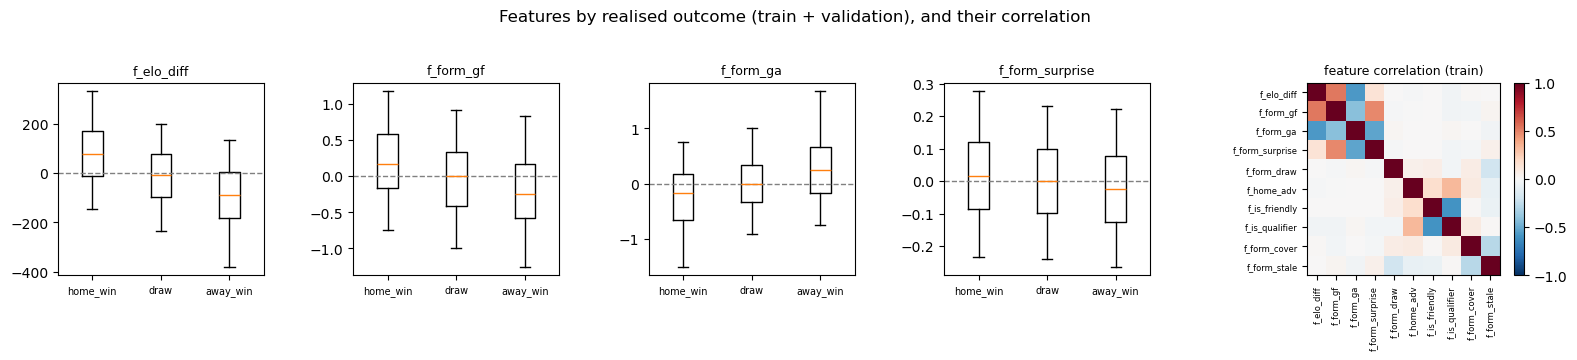

In [14]:
diag = model_df[model_df["period"].isin(["train", "validation"])]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.4]})
for ax, col in zip(axes, ["f_elo_diff", "f_form_gf", "f_form_ga", "f_form_surprise"]):
    ax.boxplot([diag.loc[diag["y"] == c, col] for c in (0, 1, 2)], showfliers=False, whis=(5, 95))
    ax.set_xticks([1, 2, 3], OUTCOMES, fontsize=7); ax.axhline(0, color="0.5", ls="--", lw=1); ax.set_title(col, fontsize=9)
C = model_df.loc[model_df["period"] == "train", FEATURES].corr()
im = axes[4].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
axes[4].set_xticks(range(10), FEATURES, rotation=90, fontsize=6); axes[4].set_yticks(range(10), FEATURES, fontsize=6)
axes[4].set_title("feature correlation (train)", fontsize=9); fig.colorbar(im, ax=axes[4], fraction=0.046)
fig.suptitle("Features by realised outcome (train + validation), and their correlation", y=1.03)
plt.tight_layout(); plt.show()

## 8. Checkpoint

In [15]:
check({"one row per working match": len(model_df) == len(matches),
       "exactly the 10 registered features": [c for c in model_df.columns if c.startswith("f_")] == FEATURES,
       "sorted by date": model_df["date"].is_monotonic_increasing,
       "no metric computed on test / WC-2026": set(ELO_K_RESULTS.index.get_level_values("period")) == {"train", "validation"}},
      "Stage 2b checkpoint")
display(model_df["period"].value_counts().reindex(PERIOD_LABELS).to_frame("rows"))

[PASS] one row per working match
[PASS] exactly the 10 registered features
[PASS] sorted by date
[PASS] no metric computed on test / WC-2026


,rows
period,
burn_in,19498
train,18914
validation,3812
test,7187
wc2026_window,105


---
# Stage 3 — Multinomial logistic regression

For a match with feature vector $x \in \mathbb{R}^d$, each class $k \in \{\text{A win}, \text{draw}, \text{B win}\}$ gets a score
$z_k = w_k^\top x + b_k$, turned into probabilities by the **softmax**:
$$p_k = \frac{e^{z_k}}{\sum_{j} e^{z_j}}.$$
Training minimises the **cross-entropy (log loss) with an L2 penalty** on the slopes (not the intercepts):
$$J(W) = -\frac{1}{n}\sum_{i=1}^{n} \log p_{i, y_i} + \frac{\lambda}{2}\lVert W \rVert_F^2, \qquad
\nabla_W J = \frac{1}{n} X^\top (P - Y) + \lambda W.$$
$J$ is convex, so any stationary point is the global optimum. It is minimised two ways, both driven by the hand-written gradient:
L-BFGS (scipy used purely as an optimiser) and hand-written batch gradient descent with Armijo backtracking.

| Formula | Code |
|---|---|
| softmax, with max-subtraction so `exp` cannot overflow | `softmax()`, `log_softmax()` |
| $J$ and $\nabla J$ | `loss_and_grad()` |
| $W \leftarrow W - \eta \nabla J$ | `SoftmaxRegression._gradient_descent()` |
| $\hat y = \arg\max_k p_k$ | `SoftmaxRegression.predict()` |

In [16]:
CLASS_LABELS, N_CLASSES = OUTCOMES, 3

def softmax(Z):
    Z = np.asarray(Z, float) - np.max(Z, axis=1, keepdims=True)       # shift-invariance: prevents overflow
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def log_softmax(Z):
    Z = np.asarray(Z, float) - np.max(Z, axis=1, keepdims=True)
    return Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))          # log-sum-exp: exact for confident forecasts

def one_hot(y, k=N_CLASSES):
    Y = np.zeros((len(y), k)); Y[np.arange(len(y)), np.asarray(y, int)] = 1.0
    return Y

def add_intercept(X):
    return np.column_stack([np.ones(len(X)), np.asarray(X, float)])

def loss_and_grad(theta, X1, Y, l2):
    """J(theta) and its gradient. X1 already has the column of ones; row 0 of W holds the intercepts."""
    n, d1 = X1.shape
    W = theta.reshape(d1, N_CLASSES)
    logP = log_softmax(X1 @ W)
    loss = -np.sum(Y * logP) / n
    G = X1.T @ (np.exp(logP) - Y) / n                                  # (1/n) X'(P - Y)
    loss += 0.5 * l2 * np.sum(W[1:] ** 2)                              # intercepts are not penalised
    G[1:] += l2 * W[1:]
    return float(loss), G.ravel()

class SoftmaxRegression:
    """Multinomial logistic regression. optimiser = 'lbfgs' (scipy, hand-written gradient) or 'gd' (hand-written)."""
    def __init__(self, l2=1e-3, optimiser="lbfgs", max_iter=2000, tol=1e-9):
        self.l2, self.optimiser, self.max_iter, self.tol = float(l2), optimiser, int(max_iter), float(tol)

    def fit(self, X, y, theta0=None):
        X1, Y = add_intercept(X), one_hot(y)
        theta = np.zeros(X1.shape[1] * N_CLASSES) if theta0 is None else np.asarray(theta0, float).copy()
        if self.optimiser == "lbfgs":
            r = minimize(loss_and_grad, theta, args=(X1, Y, self.l2), jac=True, method="L-BFGS-B",
                         options={"maxiter": self.max_iter, "gtol": self.tol, "ftol": 1e-16})
            theta, self.n_iter_, self.converged_, self.history_ = r.x, int(r.nit), bool(r.success), None
        else:
            theta, self.n_iter_, self.converged_, self.history_ = self._gradient_descent(theta, X1, Y)
        self.loss_, g = loss_and_grad(theta, X1, Y, self.l2)
        self.grad_norm_ = float(np.max(np.abs(g)))
        self.converged_ = self.converged_ or self.grad_norm_ < 1e-6    # convex: tiny gradient = optimum
        W = theta.reshape(X1.shape[1], N_CLASSES)
        self.intercept_, self.coef_, self.theta_ = W[0].copy(), W[1:].T.copy(), theta
        self.n_params_ = theta.size
        return self

    def _gradient_descent(self, theta, X1, Y):
        """Batch gradient descent with Armijo backtracking line search."""
        eta, c1, hist = 1.0, 1e-4, []
        loss, grad = loss_and_grad(theta, X1, Y, self.l2)
        for it in range(self.max_iter):
            gnorm = float(np.max(np.abs(grad)))
            hist.append((it, loss, gnorm))
            if gnorm < self.tol:
                return theta, it, True, hist
            step = eta
            for _ in range(60):                                        # halve the step until J decreases enough
                cand = theta - step * grad
                cand_loss, cand_grad = loss_and_grad(cand, X1, Y, self.l2)
                if cand_loss <= loss - c1 * step * float(grad @ grad):
                    break
                step *= 0.5
            theta, loss, grad = cand, cand_loss, cand_grad
            eta = min(step * 2.0, 1e4)                                 # let the step grow again
        return theta, self.max_iter, False, hist

    def predict_proba(self, X):
        return softmax(add_intercept(X) @ np.vstack([self.intercept_, self.coef_.T]))

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

class TrainFittedScaler:
    """z-scores whose mean and sd come from the TRAIN rows only, then are applied unchanged to other periods."""
    def fit(self, X):
        X = np.asarray(X, float)
        self.mean_, sd = X.mean(axis=0), X.std(axis=0)
        self.scale_ = np.where(sd < 1e-12, 1.0, sd)
        return self
    def transform(self, X):
        return (np.asarray(X, float) - self.mean_) / self.scale_

### 9.1 Correctness tests
The gradient check is the important one: a wrong gradient still converges, just to the wrong answer.

In [17]:
rng = np.random.default_rng(SEED + 11)
Xg, yg = rng.normal(size=(120, 6)), rng.integers(0, 3, size=120)
X1g, Yg = add_intercept(Xg), one_hot(yg)
th = rng.normal(scale=0.4, size=X1g.shape[1] * 3)
analytic = loss_and_grad(th, X1g, Yg, 0.07)[1]
numeric = np.array([(loss_and_grad(th + e, X1g, Yg, 0.07)[0] - loss_and_grad(th - e, X1g, Yg, 0.07)[0]) / 2e-6
                    for e in np.eye(th.size) * 1e-6])
rel_err = np.max(np.abs(analytic - numeric)) / np.max(np.abs(analytic) + np.abs(numeric))

Z = rng.normal(scale=3, size=(50, 3))
m_lb = SoftmaxRegression(0.05, "lbfgs", tol=1e-10).fit(Xg, yg)
m_gd = SoftmaxRegression(0.05, "gd", max_iter=6000).fit(Xg, yg)

Xs = rng.normal(size=(60000, 4)); W_true = rng.normal(scale=0.9, size=(3, 4))          # synthetic ground truth
ys = (rng.random(60000)[:, None] > np.cumsum(softmax(Xs @ W_true.T + [0.4, -0.2, -0.2]), axis=1)).sum(axis=1)
m_syn = SoftmaxRegression(1e-6, tol=1e-11).fit(Xs, ys)
centre = lambda W: W - W.mean(axis=0)                                  # only contrasts are identifiable

from sklearn.linear_model import LogisticRegression                    # used ONLY to cross-check
sk = LogisticRegression(C=1 / (len(yg) * 0.05), max_iter=5000, tol=1e-10).fit(Xg, yg)

check({f"G1 analytic gradient = finite differences (rel err {rel_err:.1e})": rel_err < 1e-6,
       "G2 softmax rows sum to 1 and are shift-invariant": np.allclose(softmax(Z).sum(1), 1) and np.allclose(softmax(Z), softmax(Z + 5)),
       "G2 no overflow at scores of +/- 1e4": np.isfinite(softmax(np.array([[1e4, -1e4, 0]]))).all(),
       "G2 K = 2 reduces to the logistic sigmoid": np.allclose(softmax(Z[:, :2])[:, 0], 1 / (1 + np.exp(Z[:, 1] - Z[:, 0]))),
       "G3 all-zero weights give loss = ln 3": np.isclose(loss_and_grad(np.zeros_like(th), X1g, Yg, 0)[0], np.log(3)),
       "G4 hand-written GD and L-BFGS reach the same optimum": abs(m_lb.loss_ - m_gd.loss_) < 1e-7,
       "G4 recovers a known generating model (60k synthetic rows)": np.max(np.abs(centre(W_true) - centre(m_syn.coef_))) < 0.06,
       "G4 sklearn reaches the same coefficients at the matching penalty": np.max(np.abs(centre(sk.coef_) - centre(m_lb.coef_))) < 1e-4},
      "model correctness tests")

[PASS] G1 analytic gradient = finite differences (rel err 4.5e-10)
[PASS] G2 softmax rows sum to 1 and are shift-invariant
[PASS] G2 no overflow at scores of +/- 1e4
[PASS] G2 K = 2 reduces to the logistic sigmoid
[PASS] G3 all-zero weights give loss = ln 3
[PASS] G4 hand-written GD and L-BFGS reach the same optimum
[PASS] G4 recovers a known generating model (60k synthetic rows)
[PASS] G4 sklearn reaches the same coefficients at the matching penalty


### 9.2 Metrics

In [18]:
def per_match_log_loss(y, P):
    return -np.log(np.clip(P, 1e-15, 1)[np.arange(len(y)), np.asarray(y, int)])

def log_loss(y, P):  return float(per_match_log_loss(y, P).mean())
def brier(y, P):     return float(np.mean(np.sum((P - one_hot(y)) ** 2, axis=1)))
def rps(y, P):       return float(np.mean(np.sum((np.cumsum(P, 1) - np.cumsum(one_hot(y), 1))[:, :-1] ** 2, axis=1)) / 2)

def confusion(y, yhat):
    cm = np.zeros((3, 3), int)
    np.add.at(cm, (np.asarray(y, int), np.asarray(yhat, int)), 1)     # rows = actual, columns = predicted
    return cm

def evaluate(y, P):
    y, yhat = np.asarray(y, int), np.argmax(P, axis=1)
    cm = confusion(y, yhat)
    tp, pred, act = np.diag(cm), cm.sum(0), cm.sum(1)
    prec = np.divide(tp, pred, out=np.zeros(3), where=pred > 0)
    rec = np.divide(tp, act, out=np.zeros(3), where=act > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(3), where=prec + rec > 0)
    row = {"n": len(y), "log_loss": log_loss(y, P), "brier": brier(y, P), "rps": rps(y, P),
           "accuracy": float((y == yhat).mean()), "macro_f1": float(f1.mean()), "weighted_f1": float(f1 @ act / act.sum())}
    row |= {f"{m}_{c}": v[i] for m, v in [("precision", prec), ("recall", rec), ("f1", f1)] for i, c in enumerate(CLASS_LABELS)}
    row |= {f"predicted_{c}": int(pred[i]) for i, c in enumerate(CLASS_LABELS)}
    return row, cm

from sklearn.metrics import log_loss as sk_ll, confusion_matrix as sk_cm, f1_score as sk_f1
yc, Pc = rng.integers(0, 3, 800), rng.dirichlet([1.5] * 3, 800)
check({"uniform forecast: log loss = ln 3, Brier = 2/3": np.isclose(log_loss(yc, np.full((800, 3), 1 / 3)), np.log(3))
                                                      and np.isclose(brier(yc, np.full((800, 3), 1 / 3)), 2 / 3),
       "RPS penalises a distant miss more than an adjacent one": rps([0], np.array([[0, 0, 1.]])) > rps([0], np.array([[0, 1., 0]])),
       "log loss matches sklearn": np.isclose(log_loss(yc, Pc), sk_ll(yc, Pc)),
       "confusion matrix matches sklearn": np.array_equal(confusion(yc, Pc.argmax(1)), sk_cm(yc, Pc.argmax(1))),
       "macro F1 matches sklearn": np.isclose(evaluate(yc, Pc)[0]["macro_f1"], sk_f1(yc, Pc.argmax(1), average="macro"))},
      "metric checks")

[PASS] uniform forecast: log loss = ln 3, Brier = 2/3
[PASS] RPS penalises a distant miss more than an adjacent one
[PASS] log loss matches sklearn
[PASS] confusion matrix matches sklearn
[PASS] macro F1 matches sklearn


## 10. Baseline (no Elo) vs Elo

In [19]:
SPLITS = ["train", "validation", "test"]
SPLIT_INDEX = {s: model_df.index[model_df["period"] == s] for s in SPLITS}
assert all(model_df.loc[SPLIT_INDEX[a], "date"].max() < model_df.loc[SPLIT_INDEX[b], "date"].min()
           for a, b in [("train", "validation"), ("validation", "test")]), "split is not chronological"

stage3_df = model_df.assign(f_form_win=build_features(matches, 20, 10, extra=True)["c_form_win"])
SHARED = ["f_form_gf", "f_form_ga", "f_form_draw", "f_home_adv", "f_is_friendly", "f_is_qualifier", "f_form_cover", "f_form_stale"]
FEATURE_SETS = {"M1 baseline (no Elo)": SHARED + ["f_form_win"], "M2 Elo-enhanced": FEATURES}

def matrices(frame, cols):
    """{split: (X_scaled, y)} with the scaler fitted on TRAIN rows only."""
    scaler = TrainFittedScaler().fit(frame.loc[SPLIT_INDEX["train"], cols])
    return {s: (scaler.transform(frame.loc[SPLIT_INDEX[s], cols]), frame.loc[SPLIT_INDEX[s], "y"].to_numpy(int))
            for s in ["train", "validation"]}, scaler

LAMBDA_GRID = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
DATA, SCALERS, MODELS, sweep_rows = {}, {}, {}, []
for name, cols in FEATURE_SETS.items():
    DATA[name], SCALERS[name] = matrices(stage3_df, cols)
    (Xtr, ytr), (Xva, yva) = DATA[name]["train"], DATA[name]["validation"]
    for lam in LAMBDA_GRID:
        m = SoftmaxRegression(lam, tol=1e-10).fit(Xtr, ytr)
        sweep_rows.append({"model": name, "lambda": lam, "train_log_loss": log_loss(ytr, m.predict_proba(Xtr)),
                           "val_log_loss": log_loss(yva, m.predict_proba(Xva)), "coef_norm": np.linalg.norm(m.coef_)})
sweep = pd.DataFrame(sweep_rows)
BEST_LAMBDA = {n: float(g.loc[g["val_log_loss"].idxmin(), "lambda"]) for n, g in sweep.groupby("model")}
for name in FEATURE_SETS:                                               # final fit: train rows only
    MODELS[name] = SoftmaxRegression(BEST_LAMBDA[name], tol=1e-10).fit(*DATA[name]["train"])
display(pd.DataFrame({n: {"features": len(FEATURE_SETS[n]), "parameters": MODELS[n].n_params_, "lambda (chosen on validation)": BEST_LAMBDA[n],
                          "L-BFGS iterations": MODELS[n].n_iter_, "max |gradient|": f"{MODELS[n].grad_norm_:.1e}"} for n in MODELS}).T)

# The reported fit does not depend on scipy: hand-written GD lands on the same optimum.
gd = SoftmaxRegression(BEST_LAMBDA["M2 Elo-enhanced"], "gd", max_iter=8000, tol=1e-8).fit(*DATA["M2 Elo-enhanced"]["train"])
print(f"M2 objective: hand-written GD {gd.loss_:.8f} ({gd.n_iter_} iterations) vs L-BFGS {MODELS['M2 Elo-enhanced'].loss_:.8f}")
assert abs(gd.loss_ - MODELS["M2 Elo-enhanced"].loss_) < 1e-6

,features,parameters,lambda (chosen on validation),L-BFGS iterations,max |gradient|
M1 baseline (no Elo),9,30,0.000001,29,1.1e-09
M2 Elo-enhanced,10,33,0.001,26,1.4e-09


M2 objective: hand-written GD 0.90374986 (60 iterations) vs L-BFGS 0.90374986


In [20]:
TRAIN_PRIOR = np.bincount(model_df.loc[SPLIT_INDEX["train"], "y"], minlength=3) / len(SPLIT_INDEX["train"])
rows, CONF = [], {}
for s in ["train", "validation"]:
    for name in FEATURE_SETS:
        X, y = DATA[name][s]
        r, CONF[(name, s)] = evaluate(y, MODELS[name].predict_proba(X))
        rows.append({"model": name, "split": s} | r)
    rows.append({"model": "REF train class prior", "split": s} | evaluate(y, np.tile(TRAIN_PRIOR, (len(y), 1)))[0])
RESULTS = pd.DataFrame(rows).set_index(["model", "split"]).sort_index()
HEADLINE = ["n", "log_loss", "brier", "rps", "accuracy", "macro_f1", "weighted_f1"]
display(RESULTS[HEADLINE].round(4))

# Is M2's validation gain larger than sampling noise? Paired bootstrap on per-match log loss.
yva = DATA["M2 Elo-enhanced"]["validation"][1]
d = (per_match_log_loss(yva, MODELS["M1 baseline (no Elo)"].predict_proba(DATA["M1 baseline (no Elo)"]["validation"][0]))
     - per_match_log_loss(yva, MODELS["M2 Elo-enhanced"].predict_proba(DATA["M2 Elo-enhanced"]["validation"][0])))
boot = d[np.random.default_rng(SEED + 31).integers(0, len(d), size=(4000, len(d)))].mean(axis=1)
print(f"Validation log-loss gain of M2 over M1: {d.mean():+.5f} nats/match, "
      f"95% CI [{np.percentile(boot, 2.5):+.5f}, {np.percentile(boot, 97.5):+.5f}], M2 better on {(d > 0).mean():.1%} of matches")

C2 = pd.DataFrame(MODELS["M2 Elo-enhanced"].coef_, index=CLASS_LABELS, columns=FEATURES)
display(C2.round(3))
per_point = (C2.loc["home_win", "f_elo_diff"] - C2.loc["away_win", "f_elo_diff"]) / SCALERS["M2 Elo-enhanced"].scale_[0]
print(f"Fitted home-vs-away log-odds per Elo point: {per_point:.5f}; Elo's own scale implies ln(10)/400 = {np.log(10) / 400:.5f}")

n  log_loss   brier     rps  accuracy  macro_f1  weighted_f1
model                 split                                                                       
M1 baseline (no Elo)  train       18914    0.9624  0.5713  0.1976    0.5420    0.3790       0.4587
                      validation   3812    0.9701  0.5760  0.1997    0.5365    0.3793       0.4535
M2 Elo-enhanced       train       18914    0.9033  0.5326  0.1794    0.5802    0.4280       0.5050
                      validation   3812    0.9041  0.5326  0.1789    0.5771    0.4259       0.4992
REF train class prior train       18914    1.0450  0.6292  0.2248    0.4896    0.2191       0.3219
                      validation   3812    1.0538  0.6357  0.2278    0.4746    0.2146       0.3055

Validation log-loss gain of M2 over M1: +0.06600 nats/match, 95% CI [+0.05474, +0.07671], M2 better on 64.5% of matches


,f_elo_diff,f_form_gf,f_form_ga,f_form_surprise,f_form_draw,f_home_adv,f_is_friendly,f_is_qualifier,f_form_cover,f_form_stale
home_win,0.679,0.016,-0.153,0.003,-0.015,0.131,-0.055,0.024,-0.030,0.080
draw,-0.049,-0.010,-0.016,0.011,0.022,0.027,0.073,-0.012,0.032,-0.098
away_win,-0.630,-0.006,0.170,-0.014,-0.008,-0.158,-0.018,-0.012,-0.002,0.018


Fitted home-vs-away log-odds per Elo point: 0.00804; Elo's own scale implies ln(10)/400 = 0.00576


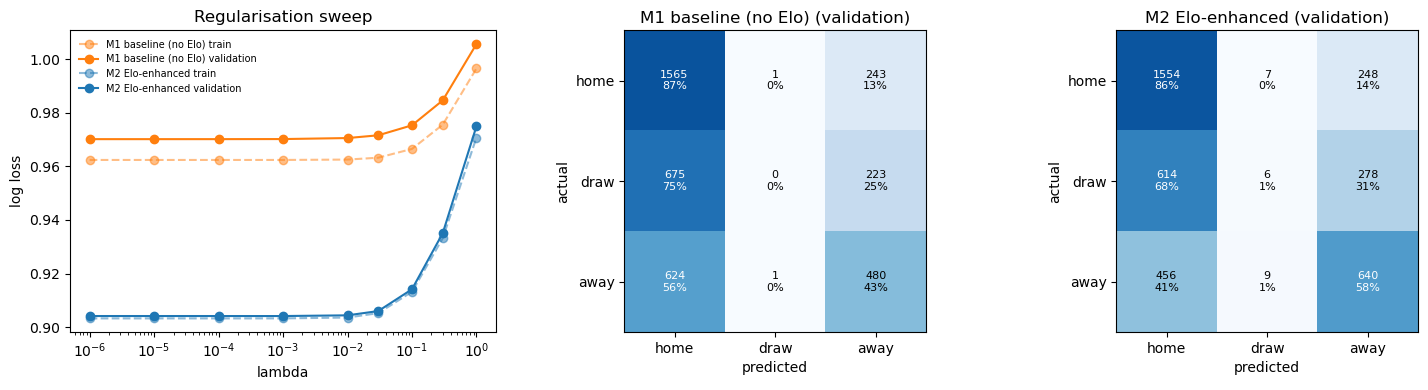

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, c in zip(FEATURE_SETS, ["C1", "C0"]):
    g = sweep[sweep["model"] == name]
    axes[0].semilogx(g["lambda"], g["train_log_loss"], "o--", color=c, alpha=0.5, label=f"{name} train")
    axes[0].semilogx(g["lambda"], g["val_log_loss"], "o-", color=c, label=f"{name} validation")
axes[0].set(title="Regularisation sweep", xlabel="lambda", ylabel="log loss"); axes[0].legend(fontsize=7, frameon=False)
for ax, name in zip(axes[1:], FEATURE_SETS):
    cm = CONF[(name, "validation")]; norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if norm[i, j] > 0.55 else "black")
    ax.set(title=f"{name} (validation)", xlabel="predicted", ylabel="actual", xticks=range(3), yticks=range(3),
           xticklabels=["home", "draw", "away"], yticklabels=["home", "draw", "away"])
plt.tight_layout(); plt.show()

**Reading.** The Elo model lowers validation log loss clearly beyond noise. Both models almost never predict a draw
(read the draw row of the confusion matrices): that is the argmax effect described in 9.2, not a failure of $p(\text{draw})$.

---
# Stage 4 — Controlled experiments (train → validation only)
One factor varies, everything else is held at the reference configuration **K = 20, N = 10, family C, C = 0.1**.
$C$ is sklearn's inverse penalty; this notebook's penalty is $\lambda = 1 / (C\, n_\text{train})$.

| Experiment | Varies | Hypothesis |
|---|---|---|
| E1 | Elo K ∈ {10, 20, 30, 40} | validation loss is U-shaped in K |
| E2 | form window N ∈ {5, 10, 20} | longer windows help, then flatten (N = 20 spans ~2 years) |
| E3 | family A basic / B +Elo / C +Elo+form / D +form, no Elo | B ≫ A; C only slightly better than B |
| E4 | C ∈ {0.003 … 3} | flat: ~19k rows for ≤ 33 parameters, so overfitting is not binding |
| E5 | C re-chosen on the combined winners | confirms the one-factor-at-a-time winners stack |

**Selection rule.** (1) lowest validation log loss; (2) configurations within 1 SE of the leader are paired-bootstrapped against it,
and those whose interval includes 0 are *ties*; (3) among ties prefer fewer features, then K and N closest to the defaults, then the stronger penalty.

In [22]:
CONTEXT = ["f_home_adv", "f_is_friendly", "f_is_qualifier"]
FEATS = {(k, w): build_features(matches, k, w, extra=True) for k in K_GRID for w in FORM_WINDOWS}
stage4_df = model_df[["date", "period", "y"] + CONTEXT].copy()             # every (K, N) variant as one wide frame
for k in K_GRID:
    stage4_df[f"x_elo_diff_k{k}"] = FEATS[(k, 10)]["f_elo_diff"]
    for w in FORM_WINDOWS:
        stage4_df[f"x_form_surprise_w{w}_k{k}"] = FEATS[(k, w)]["f_form_surprise"]
for w in FORM_WINDOWS:
    for new, old in [("gf", "f_form_gf"), ("ga", "f_form_ga"), ("draw", "f_form_draw"), ("cover", "f_form_cover"),
                     ("stale", "f_form_stale"), ("win", "c_form_win")]:
        stage4_df[f"x_form_{new}_w{w}"] = FEATS[(20, w)][old]
assert np.isfinite(stage4_df.filter(like="x_").to_numpy()).all()

FAMILIES = ["A basic", "B basic+Elo", "C basic+Elo+form", "D basic+form (no Elo)"]

def feature_columns_for(k, w, family):
    form = [f"x_form_gf_w{w}", f"x_form_ga_w{w}", f"x_form_surprise_w{w}_k{k}", f"x_form_draw_w{w}", f"x_form_cover_w{w}", f"x_form_stale_w{w}"]
    form_no_elo = [f"x_form_gf_w{w}", f"x_form_ga_w{w}", f"x_form_win_w{w}", f"x_form_draw_w{w}", f"x_form_cover_w{w}", f"x_form_stale_w{w}"]
    return {"A basic": CONTEXT, "B basic+Elo": CONTEXT + [f"x_elo_diff_k{k}"],
            "C basic+Elo+form": CONTEXT + [f"x_elo_diff_k{k}"] + form, "D basic+form (no Elo)": CONTEXT + form_no_elo}[family]

N_TRAIN = len(SPLIT_INDEX["train"])
RUN_CACHE, RUN_LOSSES = {}, {}

def run_config(k, w, family, C, experiment="", level=""):
    """Fit one configuration on TRAIN, score it on VALIDATION. The test split is not reachable from here."""
    key = (int(k), int(w), family, float(C))
    if key not in RUN_CACHE:
        cols = feature_columns_for(k, w, family)
        data, _ = matrices(stage4_df, cols)
        model = SoftmaxRegression(1 / (C * N_TRAIN), tol=1e-10).fit(*data["train"])
        (Xtr, ytr), (Xva, yva) = data["train"], data["validation"]
        pm = per_match_log_loss(yva, model.predict_proba(Xva))
        r, _ = evaluate(yva, model.predict_proba(Xva))
        RUN_LOSSES[key] = pm
        RUN_CACHE[key] = {"k": key[0], "window": key[1], "family": family, "C": key[3], "lambda": 1 / (C * N_TRAIN),
                          "n_features": len(cols), "val_log_loss": pm.mean(), "val_log_loss_se": pm.std(ddof=1) / np.sqrt(len(pm)),
                          "val_brier": r["brier"], "val_accuracy": r["accuracy"], "val_macro_f1": r["macro_f1"], "val_rps": r["rps"],
                          "val_f1_draw": r["f1_draw"], "train_log_loss": log_loss(ytr, model.predict_proba(Xtr)),
                          "coef_norm": np.linalg.norm(model.coef_), "model": model}
    return {kk: v for kk, v in RUN_CACHE[key].items() if kk != "model"} | {"experiment": experiment, "level": level}

K_REF, N_REF, FAMILY_REF, C_REF = 20, 10, "C basic+Elo+form", 0.1
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
E1 = pd.DataFrame([run_config(k, N_REF, FAMILY_REF, C_REF, "E1 Elo K-factor", f"K = {k}") for k in K_GRID])
E2 = pd.DataFrame([run_config(K_REF, w, FAMILY_REF, C_REF, "E2 Recent-form window", f"N = {w}") for w in FORM_WINDOWS])
E3 = pd.DataFrame([run_config(K_REF, N_REF, f, C_REF, "E3 Feature combinations", f) for f in FAMILIES])
E4 = pd.DataFrame([run_config(K_REF, N_REF, FAMILY_REF, c, "E4 Regularisation strength", f"C = {c:g}") for c in C_GRID])
SHOW = ["level", "n_features", "val_log_loss", "val_log_loss_se", "val_brier", "val_accuracy", "val_macro_f1", "val_rps", "train_log_loss"]
for E in (E1, E2, E3, E4):
    print(E["experiment"].iloc[0]); display(E[SHOW].set_index("level").round(5))

E1 Elo K-factor


,n_features,val_log_loss,val_log_loss_se,val_brier,val_accuracy,val_macro_f1,val_rps,train_log_loss
level,,,,,,,,
K = 10,10,0.91350,0.00967,0.53845,0.57660,0.42496,0.18161,0.91076
K = 20,10,0.90413,0.00971,0.53255,0.57686,0.42572,0.17894,0.90325
K = 30,10,0.90047,0.00972,0.53029,0.57817,0.42809,0.17794,0.90048
K = 40,10,0.89903,0.00973,0.52941,0.57870,0.42747,0.17756,0.89955


E2 Recent-form window


,n_features,val_log_loss,val_log_loss_se,val_brier,val_accuracy,val_macro_f1,val_rps,train_log_loss
level,,,,,,,,
N = 5,10,0.90412,0.00968,0.53286,0.57660,0.42516,0.17918,0.90430
N = 10,10,0.90413,0.00971,0.53255,0.57686,0.42572,0.17894,0.90325
N = 20,10,0.90437,0.00969,0.53271,0.57922,0.42689,0.17914,0.90230


E3 Feature combinations


,n_features,val_log_loss,val_log_loss_se,val_brier,val_accuracy,val_macro_f1,val_rps,train_log_loss
level,,,,,,,,
A basic,3,1.04753,0.00560,0.63160,0.47455,0.21455,0.22615,1.03886
B basic+Elo,4,0.91006,0.00960,0.53648,0.57529,0.41928,0.18036,0.91138
C basic+Elo+form,10,0.90413,0.00971,0.53255,0.57686,0.42572,0.17894,0.90325
D basic+form (no Elo),9,0.97015,0.00823,0.57602,0.53646,0.37926,0.19972,0.96237


E4 Regularisation strength


,n_features,val_log_loss,val_log_loss_se,val_brier,val_accuracy,val_macro_f1,val_rps,train_log_loss
level,,,,,,,,
C = 0.003,10,0.90490,0.00927,0.53309,0.57844,0.42328,0.17918,0.90410
C = 0.01,10,0.90420,0.00957,0.53262,0.57817,0.42617,0.17897,0.90335
C = 0.03,10,0.90414,0.00967,0.53256,0.57739,0.42595,0.17895,0.90327
C = 0.1,10,0.90413,0.00971,0.53255,0.57686,0.42572,0.17894,0.90325
C = 0.3,10,0.90414,0.00972,0.53255,0.57686,0.42575,0.17894,0.90325
C = 1,10,0.90414,0.00973,0.53255,0.57686,0.42572,0.17894,0.90325
C = 3,10,0.90414,0.00973,0.53255,0.57686,0.42572,0.17894,0.90325


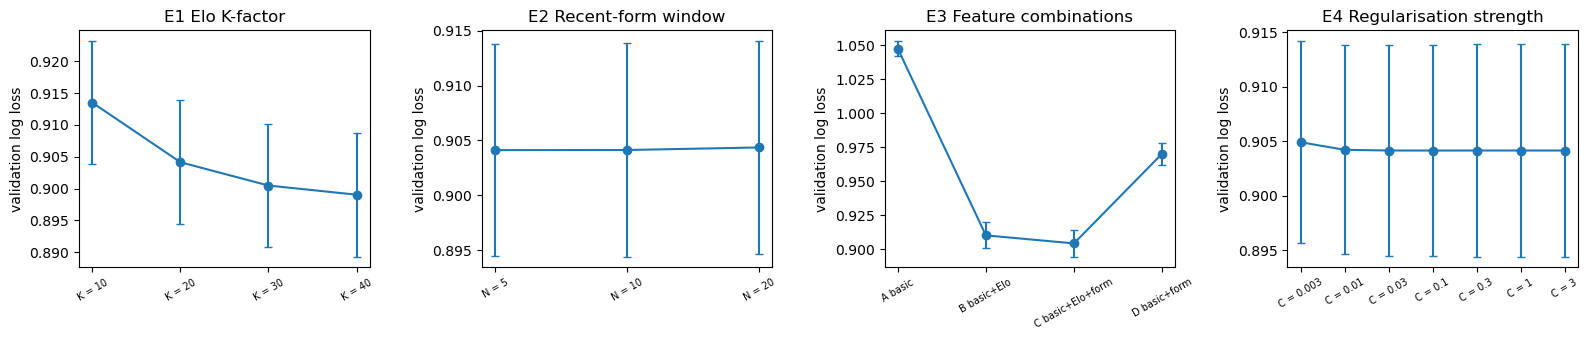

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, E in zip(axes, (E1, E2, E3, E4)):
    ax.errorbar(range(len(E)), E["val_log_loss"], yerr=E["val_log_loss_se"], fmt="o-", capsize=3)
    ax.set_xticks(range(len(E)), [l.split(" (")[0] for l in E["level"]], rotation=30, fontsize=7)
    ax.set(title=E["experiment"].iloc[0], ylabel="validation log loss")
plt.tight_layout(); plt.show()

### 11.1 Selection (validation log loss; test untouched)

In [24]:
COLS = ["experiment", "level", "k", "window", "family", "C", "lambda", "n_features", "val_log_loss", "val_log_loss_se",
        "val_brier", "val_accuracy", "val_macro_f1", "val_f1_draw", "val_rps", "train_log_loss"]
EXPERIMENT_RESULTS = pd.concat([E1, E2, E3, E4], ignore_index=True)[COLS].sort_values(["experiment", "val_log_loss"], kind="stable").reset_index(drop=True)
winners = EXPERIMENT_RESULTS.loc[EXPERIMENT_RESULTS.groupby("experiment")["val_log_loss"].idxmin()].set_index("experiment")
key_of = lambda r: (int(r["k"]), int(r["window"]), r["family"], float(r["C"]))

boot_rng = np.random.default_rng(SEED + 41)
REF_KEY = (K_REF, N_REF, FAMILY_REF, float(C_REF))

def paired_vs(key, label, ref_key=REF_KEY):
    """Paired bootstrap of (reference - candidate) per-match validation log loss. Positive = candidate better."""
    d = RUN_LOSSES[ref_key] - RUN_LOSSES[key]
    means = d[boot_rng.integers(0, len(d), size=(4000, len(d)))].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return {"configuration": label, "mean log-loss gain": d.mean(), "95% CI low": lo, "95% CI high": hi,
            "interval excludes zero": bool(lo > 0 or hi < 0)}

display(pd.DataFrame([paired_vs(key_of(r), f"{e}: {r['level']}") for e, r in winners.iterrows() if key_of(r) != REF_KEY])
        .set_index("configuration").round(5))

K_STAR, N_STAR, FAMILY_STAR = int(winners.loc["E1 Elo K-factor", "k"]), int(winners.loc["E2 Recent-form window", "window"]), \
                              winners.loc["E3 Feature combinations", "family"]
E5 = pd.DataFrame([run_config(K_STAR, N_STAR, FAMILY_STAR, c, "E5 Confirmation (combined winners)", f"C = {c:g}") for c in C_GRID])
EXPERIMENT_RESULTS = pd.concat([EXPERIMENT_RESULTS, E5[COLS]], ignore_index=True)
ALL_RUNS = (pd.concat([E1, E2, E3, E4, E5], ignore_index=True)[COLS].drop_duplicates(["k", "window", "family", "C"])
            .sort_values("val_log_loss", kind="stable").reset_index(drop=True))

# Rule 1 and 2: the leader, a 1-SE screen, then a paired test of each survivor against the leader.
leader = ALL_RUNS.iloc[0]
screen = ALL_RUNS[ALL_RUNS["val_log_loss"] <= leader["val_log_loss"] + leader["val_log_loss_se"]]
ties = []
for _, r in screen.iterrows():
    lab = f"K={int(r['k'])}, N={int(r['window'])}, {r['family'][0]}, C={r['C']:g}"
    t = ({"configuration": lab, "interval excludes zero": False} if key_of(r) == key_of(leader)
         else paired_vs(key_of(r), lab, ref_key=key_of(leader)))
    ties.append(t | {"k": int(r["k"]), "window": int(r["window"]), "family": r["family"], "C": r["C"],
                     "n_features": int(r["n_features"]), "val_log_loss": r["val_log_loss"]})
ties = pd.DataFrame(ties)
# Rule 3: among genuine ties, fewer features, then K and N closest to the defaults, then the stronger penalty.
tied = ties[~ties["interval excludes zero"]].assign(dK=lambda t: (t["k"] - 20).abs(), dN=lambda t: (t["window"] - 10).abs(),
                                                     logC=lambda t: np.log10(t["C"]))
chosen = tied.sort_values(["n_features", "dK", "dN", "logC"], kind="stable").iloc[0]
display(ties.set_index("configuration")[["val_log_loss", "mean log-loss gain", "95% CI low", "95% CI high", "interval excludes zero"]].round(5))

sel = ALL_RUNS[(ALL_RUNS[["k", "window", "family", "C"]] == [chosen["k"], chosen["window"], chosen["family"], chosen["C"]]).all(axis=1)].iloc[0]
BEST_CONFIG = {"k": int(sel["k"]), "window": int(sel["window"]), "family": sel["family"], "C": float(sel["C"]),
               "lambda": float(sel["lambda"]), "features": feature_columns_for(int(sel["k"]), int(sel["window"]), sel["family"]),
               "val_log_loss": float(sel["val_log_loss"]), "val_log_loss_se": float(sel["val_log_loss_se"])}
print(f"BEST CONFIG: K = {BEST_CONFIG['k']}, N = {BEST_CONFIG['window']}, {BEST_CONFIG['family']}, C = {BEST_CONFIG['C']:g} "
      f"-> validation log loss {BEST_CONFIG['val_log_loss']:.5f} +/- {BEST_CONFIG['val_log_loss_se']:.5f} "
      f"({len(ALL_RUNS)} configurations compared, no test row read)")
display(pd.DataFrame([paired_vs(key_of(sel), "selected vs reference config")]).set_index("configuration").round(5))

,mean log-loss gain,95% CI low,95% CI high,interval excludes zero
configuration,,,,
E1 Elo K-factor: K = 40,0.00510,0.00241,0.00772,True
E2 Recent-form window: N = 5,0.00001,-0.00244,0.00248,False


,val_log_loss,mean log-loss gain,95% CI low,95% CI high,interval excludes zero
configuration,,,,,
"K=40, N=5, C, C=1",0.89812,NaN,NaN,NaN,False
"K=40, N=5, C, C=3",0.89812,-0.00000,-0.00000,0.00000,False
"K=40, N=5, C, C=0.3",0.89812,-0.00000,-0.00001,0.00001,False
"K=40, N=5, C, C=0.1",0.89812,-0.00000,-0.00005,0.00005,False
"K=40, N=5, C, C=0.03",0.89813,-0.00001,-0.00018,0.00015,False
"K=40, N=5, C, C=0.01",0.89823,-0.00011,-0.00057,0.00040,False
"K=40, N=10, C, C=0.1",0.89903,-0.00091,-0.00283,0.00096,False
"K=40, N=5, C, C=0.003",0.89912,-0.00100,-0.00243,0.00044,False
"K=30, N=10, C, C=0.1",0.90047,-0.00235,-0.00462,-0.00013,True


BEST CONFIG: K = 40, N = 10, C basic+Elo+form, C = 0.1 -> validation log loss 0.89903 +/- 0.00973 (22 configurations compared, no test row read)


,mean log-loss gain,95% CI low,95% CI high,interval excludes zero
configuration,,,,
selected vs reference config,0.0051,0.00241,0.00768,True


In [25]:
# ---- 11.2 Disclosed post-hoc check: E1 selected K = 40 at the edge of the grid --------------------
# The pre-registered grid {10, 20, 30, 40} is NOT extended retrospectively for selection. This measures,
# on VALIDATION only, whether the optimum lies outside it, so the limitation is quantified, not asserted.
def elo_k_val(k, w=N_REF, C=C_REF):
    e = ELO[k][0] if k in ELO else elo_pass(matches, k)[0]
    f = build_features(matches, k=k, w=w, elo=e)
    frame = model_df[["date", "period", "y"] + CONTEXT].copy()
    frame["x_elo_diff"] = f["f_elo_diff"]
    for new_, old_ in [("gf", "f_form_gf"), ("ga", "f_form_ga"), ("surprise", "f_form_surprise"),
                       ("draw", "f_form_draw"), ("cover", "f_form_cover"), ("stale", "f_form_stale")]:
        frame[f"x_{new_}"] = f[old_]
    cols = CONTEXT + ["x_elo_diff"] + [f"x_{c}" for c in ["gf", "ga", "surprise", "draw", "cover", "stale"]]
    data, _ = matrices(frame, cols)
    m_ = SoftmaxRegression(1 / (C * N_TRAIN), tol=1e-10).fit(*data["train"])
    return log_loss(data["validation"][1], m_.predict_proba(data["validation"][0]))

K_EXTENDED = pd.DataFrame([{"K": k, "validation log loss": elo_k_val(k)} for k in [30, 40, 50, 60, 80]]).set_index("K")
display(K_EXTENDED.round(5))
print("Reported as a limitation rather than a selection: 'K = 40' means 'best of the pre-registered grid', and the "
      "frozen model below still uses that winner. A wider grid is future work.")

,validation log loss
K,
30,0.90047
40,0.89903
50,0.89863
60,0.89877
80,0.89981


Reported as a limitation rather than a selection: 'K = 40' means 'best of the pre-registered grid', and the frozen model below still uses that winner. A wider grid is future work.


---
# Stage 5 — Frozen models and test evaluation
The baseline gets the **same** selection protocol as the Elo model (its own N and C, chosen on validation), so it is not handicapped.
Two nested models isolate the rating itself: **A** = 3 context dummies, **B** = A + `elo_diff` (one column differs).
All four are fitted on train rows only and frozen. Only then is the test period opened, once.

In [26]:
bk = BEST_CONFIG["k"]
BASE_SWEEP = pd.DataFrame([run_config(bk, w, "D basic+form (no Elo)", c) for w in FORM_WINDOWS for c in C_GRID]).sort_values("val_log_loss", kind="stable")
A_SWEEP = pd.DataFrame([run_config(bk, BEST_CONFIG["window"], "A basic", c) for c in C_GRID]).sort_values("val_log_loss", kind="stable")
B_SWEEP = pd.DataFrame([run_config(k, BEST_CONFIG["window"], "B basic+Elo", c) for k in K_GRID for c in C_GRID]).sort_values("val_log_loss", kind="stable")
base, a_best, b_best = BASE_SWEEP.iloc[0], A_SWEEP.iloc[0], B_SWEEP.iloc[0]

TEST_OPEN = False

def freeze(name, k, w, family, C):
    cols = feature_columns_for(k, w, family)
    scaler = TrainFittedScaler().fit(stage4_df.loc[SPLIT_INDEX["train"], cols])
    model = SoftmaxRegression(1 / (C * N_TRAIN), tol=1e-10).fit(scaler.transform(stage4_df.loc[SPLIT_INDEX["train"], cols]),
                                                               stage4_df.loc[SPLIT_INDEX["train"], "y"].to_numpy(int))
    return {"name": name, "k": int(k), "window": int(w), "family": family, "C": float(C), "lambda": 1 / (C * N_TRAIN),
            "columns": cols, "scaler": scaler, "model": model}

def design(frozen, split):
    if split == "test" and not TEST_OPEN:
        raise RuntimeError("test is sealed until the models are frozen")
    idx = SPLIT_INDEX[split]
    return frozen["scaler"].transform(stage4_df.loc[idx, frozen["columns"]]), stage4_df.loc[idx, "y"].to_numpy(int)

FROZEN = {"BASE": freeze("BASE", int(base["k"]), int(base["window"]), "D basic+form (no Elo)", base["C"]),
          "ELO": freeze("ELO", bk, BEST_CONFIG["window"], BEST_CONFIG["family"], BEST_CONFIG["C"]),
          "A": freeze("A", bk, BEST_CONFIG["window"], "A basic", a_best["C"]),
          "B": freeze("B", int(b_best["k"]), BEST_CONFIG["window"], "B basic+Elo", b_best["C"])}
MODEL_ORDER = list(FROZEN)
display(pd.DataFrame({n: {"family": f["family"], "K": f["k"], "N": f["window"], "C": f["C"], "features": len(f["columns"]),
                          "val log loss": RUN_CACHE[(f["k"], f["window"], f["family"], f["C"])]["val_log_loss"]}
                      for n, f in FROZEN.items()}).T)

# Option 1 check: the frozen ELO model reproduced with the hand-written optimiser.
Xtr, ytr = design(FROZEN["ELO"], "train"); Xva, _ = design(FROZEN["ELO"], "validation")
gd = SoftmaxRegression(FROZEN["ELO"]["lambda"], "gd", max_iter=20000, tol=1e-9).fit(Xtr, ytr)
dp = np.max(np.abs(gd.predict_proba(Xva) - FROZEN["ELO"]["model"].predict_proba(Xva)))
print(f"Hand-written GD reproduces the frozen ELO model: {gd.n_iter_} iterations, max |probability difference| = {dp:.1e}")
assert gd.converged_ and dp < 1e-6

# The frozen models are fingerprinted BEFORE the test seal breaks; 12.x re-checks the hashes afterwards,
# so any later change to a coefficient or a scaler constant is caught rather than argued about.
def fingerprint(f):
    payload = "|".join([f["name"], f["family"], str(f["k"]), str(f["window"]), f"{f['C']:.10g}", ",".join(f["columns"]),
                        np.array2string(f["model"].theta_, precision=12, floatmode="fixed"),
                        np.array2string(f["scaler"].mean_, precision=12, floatmode="fixed"),
                        np.array2string(f["scaler"].scale_, precision=12, floatmode="fixed")])
    return hashlib.sha256(payload.encode()).hexdigest()[:16]

FINGERPRINTS = {n: fingerprint(f) for n, f in FROZEN.items()}
print("Frozen fingerprints: " + ", ".join(f"{n} {h}" for n, h in FINGERPRINTS.items()))


,family,K,N,C,features,val log loss
BASE,D basic+form (no Elo),40,20,0.003,9,0.956922
ELO,C basic+Elo+form,40,10,0.1,10,0.899031
A,A basic,40,10,0.01,3,1.04752
B,B basic+Elo,40,10,0.03,4,0.902029


Hand-written GD reproduces the frozen ELO model: 65 iterations, max |probability difference| = 2.0e-08
Frozen fingerprints: BASE 57d81d5a64a8dc24, ELO 002bb02606405db8, A 33853d0abf1ae69b, B 77fecbcfaf999a7a


## 12. Test results (read once)

In [27]:
TEST_OPEN = True
TEST_IDX = SPLIT_INDEX["test"]
TEST_Y = stage4_df.loc[TEST_IDX, "y"].to_numpy(int)
PROBA = {n: f["model"].predict_proba(design(f, "test")[0]) for n, f in FROZEN.items()}
PROBA |= {"REF prior": np.tile(TRAIN_PRIOR, (len(TEST_Y), 1)), "REF uniform": np.full((len(TEST_Y), 3), 1 / 3)}
PER_MATCH_LL = {n: per_match_log_loss(TEST_Y, P) for n, P in PROBA.items()}

BOOT_CALLS = [0]
def boot_mean_ci(x, n_boot=4000, seed=None, chunk=250):
    """Percentile bootstrap of a mean. Matches are not independent (teams recur), so the interval is indicative."""
    if seed is None:                       # a distinct stream per call: CIs must not share resamples
        BOOT_CALLS[0] += 1; seed = SEED + 51 + 1000 * BOOT_CALLS[0]
    g, means = np.random.default_rng(seed), np.empty(n_boot)
    for s in range(0, n_boot, chunk):
        m = min(chunk, n_boot - s)
        means[s:s + m] = x[g.integers(0, len(x), size=(m, len(x)))].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi)

rows = []
for n, P in PROBA.items():
    r, _ = evaluate(TEST_Y, P)
    _, lo, hi = boot_mean_ci(PER_MATCH_LL[n])
    rows.append({"model": n} | r | {"log_loss_ci_low": lo, "log_loss_ci_high": hi})
TEST_RESULTS = pd.DataFrame(rows).set_index("model")
display(TEST_RESULTS[["n", "log_loss", "log_loss_ci_low", "log_loss_ci_high", "brier", "rps", "accuracy", "macro_f1", "weighted_f1"]].round(5))

GAP = pd.DataFrame({n: {s: log_loss(design(f, s)[1], f["model"].predict_proba(design(f, s)[0])) for s in ["train", "validation"]}
                       | {"test": TEST_RESULTS.loc[n, "log_loss"]} for n, f in FROZEN.items()}).T
H = lambda P: float(-(P * np.log(P)).sum(1).mean())                    # expected log loss if calibrated = mean entropy
GAP["ELO expected loss (entropy)"] = np.nan
GAP.loc["ELO", "ELO expected loss (entropy)"] = H(PROBA["ELO"])
display(GAP.round(5))
print(f"Test loss below train loss is explained by easier fixtures, not leakage: the ELO model's own expected loss "
      f"falls too (train {H(FROZEN['ELO']['model'].predict_proba(Xtr)):.4f} -> test {H(PROBA['ELO']):.4f}).")

,n,log_loss,log_loss_ci_low,log_loss_ci_high,brier,rps,accuracy,macro_f1,weighted_f1
model,,,,,,,,,
BASE,7187,0.93845,0.92678,0.94975,0.55479,0.19112,0.56101,0.39909,0.47935
ELO,7187,0.86535,0.85099,0.87952,0.50837,0.16921,0.60498,0.44412,0.52515
A,7187,1.04491,1.03686,1.05278,0.62970,0.22698,0.47906,0.21593,0.31033
B,7187,0.86858,0.85470,0.88234,0.51063,0.16980,0.60442,0.44078,0.52262
REF prior,7187,1.04997,1.04238,1.05753,0.63312,0.22863,0.47906,0.21593,0.31033
REF uniform,7187,1.09861,1.09861,1.09861,0.66667,0.23984,0.47906,0.21593,0.31033


,train,validation,test,ELO expected loss (entropy)
BASE,0.94497,0.95692,0.93845,NaN
ELO,0.89955,0.89903,0.86535,0.85862
A,1.03886,1.04752,1.04491,NaN
B,0.90464,0.90203,0.86858,NaN


Test loss below train loss is explained by easier fixtures, not leakage: the ELO model's own expected loss falls too (train 0.9001 -> test 0.8586).


### 12.1 Calibration: can the probabilities be read literally?

,ECE home_win,ECE draw,ECE away_win,top-label ECE,temperature T (not applied)
BASE,0.0231,0.0126,0.0199,0.0153,0.9489
ELO,0.0246,0.0126,0.0179,0.0147,1.0209
A,0.0162,0.0042,0.0116,0.0162,1.0691
B,0.0292,0.0150,0.0168,0.0192,1.0369


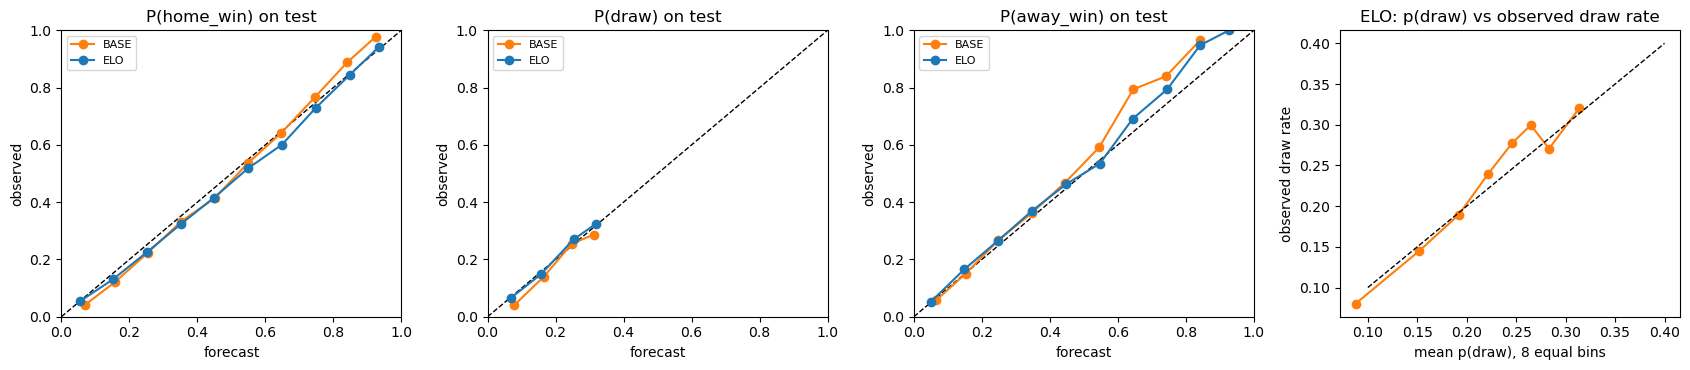

Draws: actual rate 0.228, ELO mean p(draw) 0.220, max p(draw) 0.371, times draw was the argmax: 23


REL (lower better)  RES (higher better)     UNC  Brier (1-vs-rest)
BASE home_win              0.0007               0.0408  0.2496             0.2094
     draw                  0.0002               0.0030  0.1758             0.1730
     away_win              0.0011               0.0340  0.2073             0.1744
ELO  home_win              0.0008               0.0644  0.2496             0.1860
     draw                  0.0002               0.0055  0.1758             0.1705
     away_win              0.0006               0.0539  0.2073             0.1540

,BASE,ELO,A,B
precision_home_win,0.5680,0.6147,0.4791,0.6130
precision_draw,0.0000,0.2609,0.0000,0.0000
precision_away_win,0.5412,0.5866,0.0000,0.5850
recall_home_win,0.8789,0.8861,1.0000,0.8888
recall_draw,0.0000,0.0037,0.0000,0.0000
recall_away_win,0.4772,0.6124,0.0000,0.6091
f1_home_win,0.6901,0.7259,0.6478,0.7255
f1_draw,0.0000,0.0072,0.0000,0.0000
f1_away_win,0.5072,0.5992,0.0000,0.5968
predicted_home_win,5327.0000,4963.0000,7187.0000,4992.0000


BASE: test confusion matrix (rows = actual, columns = predicted)


,pred home_win,pred draw,pred away_win
actual home_win,3026,1,416
actual draw,1199,0,437
actual away_win,1102,0,1006


ELO: test confusion matrix (rows = actual, columns = predicted)


,pred home_win,pred draw,pred away_win
actual home_win,3051,7,385
actual draw,1105,6,525
actual away_win,807,10,1291


In [28]:
BINS = np.linspace(0, 1, 11)

def reliability(hit, p):
    idx = np.clip(np.digitize(p, BINS) - 1, 0, 9)
    t = pd.DataFrame({"b": idx, "p": p, "hit": hit}).groupby("b").agg(n=("p", "size"), forecast=("p", "mean"), observed=("hit", "mean"))
    return t, float((t["n"] * (t["observed"] - t["forecast"]).abs()).sum() / len(p))

def temperature(y, P):
    """T minimising log loss of softmax(log P / T). T > 1 means the forecast was overconfident. Measured, NOT applied."""
    r = minimize_scalar(lambda lt: log_loss(y, softmax(np.log(P) / np.exp(lt))), bounds=(np.log(0.2), np.log(5)), method="bounded")
    return float(np.exp(r.x)), float(r.fun)

CALIBRATION = pd.DataFrame({n: {f"ECE {c}": reliability((TEST_Y == k).astype(float), PROBA[n][:, k])[1] for k, c in enumerate(CLASS_LABELS)}
                               | {"top-label ECE": reliability((PROBA[n].argmax(1) == TEST_Y).astype(float), PROBA[n].max(1))[1],
                                  "temperature T (not applied)": temperature(TEST_Y, PROBA[n])[0]} for n in MODEL_ORDER}).T
display(CALIBRATION.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (k, c) in zip(axes, enumerate(CLASS_LABELS)):
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    for n, col in [("BASE", "C1"), ("ELO", "C0")]:
        t, _ = reliability((TEST_Y == k).astype(float), PROBA[n][:, k])
        t = t[t["n"] >= 30]
        ax.plot(t["forecast"], t["observed"], "o-", color=col, label=n)
    ax.set(title=f"P({c}) on test", xlabel="forecast", ylabel="observed", xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=8)
q = pd.qcut(PROBA["ELO"][:, 1], 8, labels=False, duplicates="drop")
dc = pd.DataFrame({"p": PROBA["ELO"][:, 1], "draw": TEST_Y == 1}).groupby(q).mean()
axes[3].plot(dc["p"], dc["draw"], "o-", color="C1"); axes[3].plot([0.1, 0.4], [0.1, 0.4], "k--", lw=1)
axes[3].set(title="ELO: p(draw) vs observed draw rate", xlabel="mean p(draw), 8 equal bins", ylabel="observed draw rate")
plt.tight_layout(); plt.show()
print(f"Draws: actual rate {(TEST_Y == 1).mean():.3f}, ELO mean p(draw) {PROBA['ELO'][:, 1].mean():.3f}, "
      f"max p(draw) {PROBA['ELO'][:, 1].max():.3f}, times draw was the argmax: {(PROBA['ELO'].argmax(1) == 1).sum()}")

# Murphy (1973) decomposition of the one-vs-rest Brier score: REL - RES + UNC. Low REL = calibrated,
# high RES = the forecast actually separates matches; UNC is the base rate's own variance and is model-free.
def murphy(hit, p, bins=BINS):
    t, _ = reliability(hit, p)
    base = hit.mean()
    rel = float((t["n"] * (t["forecast"] - t["observed"]) ** 2).sum() / len(p))
    res = float((t["n"] * (t["observed"] - base) ** 2).sum() / len(p))
    return {"REL (lower better)": rel, "RES (higher better)": res, "UNC": float(base * (1 - base))}

MURPHY = pd.DataFrame({(n, c): murphy((TEST_Y == k).astype(float), PROBA[n][:, k])
                       for n in ["BASE", "ELO"] for k, c in enumerate(CLASS_LABELS)}).T
MURPHY["Brier (1-vs-rest)"] = MURPHY["REL (lower better)"] - MURPHY["RES (higher better)"] + MURPHY["UNC"]
display(MURPHY.round(4))

PER_CLASS = pd.DataFrame({n: {k: v for k, v in evaluate(TEST_Y, PROBA[n])[0].items()
                              if k.startswith(("precision", "recall", "f1", "predicted"))} for n in MODEL_ORDER})
display(PER_CLASS.round(4))
for n in ["BASE", "ELO"]:
    cm = confusion(TEST_Y, PROBA[n].argmax(1))
    print(f"{n}: test confusion matrix (rows = actual, columns = predicted)")
    display(pd.DataFrame(cm, index=[f"actual {c}" for c in CLASS_LABELS], columns=[f"pred {c}" for c in CLASS_LABELS]))


### 12.2 What shape of draw probability can this hypothesis space express?

Writing the draw score as the reference, $p(\text{draw}\mid d) = 1/\big(1 + e^{\alpha + \beta d} + e^{\gamma - \delta d}\big)$,
which is **unimodal in the rating gap $d$**: a linear softmax *can* place a draw peak near $d \approx 0$. What it cannot do is
set the height and width of that peak independently of the win/loss slopes $\beta$ and $\delta$. The cell below traces the frozen
model's $p(\text{draw})$ along $d$, then tests on **validation only** whether one extra shape column $|d|$ improves draw calibration.
Nothing here changes a frozen model and no test row is read.

In [29]:
F_ = FROZEN["ELO"]; jd = F_["columns"].index(f"x_elo_diff_k{F_['k']}")
grid = np.linspace(-600, 600, 121)
Xg = np.zeros((len(grid), len(F_["columns"])))                     # every other feature at its training mean
Xg[:, jd] = (grid - F_["scaler"].mean_[jd]) / F_["scaler"].scale_[jd]
p_draw_curve = F_["model"].predict_proba(Xg)[:, 1]
print(f"p(draw) peaks at d = {grid[np.argmax(p_draw_curve)]:+.0f} (p = {p_draw_curve.max():.3f}); "
      f"at d = -400 / +400 it is {p_draw_curve[grid == -400][0]:.3f} / {p_draw_curve[grid == 400][0]:.3f}. "
      "The peak sits off zero because home advantage offsets the rating gap.")

s4 = stage4_df.copy(); s4["x_abs_elo"] = s4[f"x_elo_diff_k{F_['k']}"].abs()
bands, pm_ = [], {}
for name, cc in [("selected (10 columns)", F_["columns"]), ("selected + |elo_diff|", F_["columns"] + ["x_abs_elo"])]:
    sc = TrainFittedScaler().fit(s4.loc[SPLIT_INDEX["train"], cc])
    m_ = SoftmaxRegression(F_["lambda"], tol=1e-10).fit(sc.transform(s4.loc[SPLIT_INDEX["train"], cc]),
                                                        s4.loc[SPLIT_INDEX["train"], "y"].to_numpy(int))
    iv = SPLIT_INDEX["validation"]; yv_ = s4.loc[iv, "y"].to_numpy(int)
    P_ = m_.predict_proba(sc.transform(s4.loc[iv, cc])); pm_[name] = per_match_log_loss(yv_, P_)
    b = pd.cut(s4.loc[iv, "x_abs_elo"], [0, 50, 150, 300, np.inf], include_lowest=True)
    t = pd.DataFrame({"|d| band": b.values, "observed draw": (yv_ == 1), "mean p(draw)": P_[:, 1]}).groupby("|d| band", observed=True).mean()
    bands.append(t.assign(model=name))
display(pd.concat(bands).round(3))
dd_ = pm_["selected (10 columns)"] - pm_["selected + |elo_diff|"]
g_, lo_, hi_ = boot_mean_ci(dd_)
print(f"validation log-loss gain from the |elo_diff| shape column: {g_:+.5f} (95% CI [{lo_:+.5f}, {hi_:+.5f}])")
print("The shape column moves p(draw) toward the observed rate at BOTH ends of the range, but the gain is not "
      "distinguishable from zero on 3,812 matches, so it is reported as future work rather than adopted.")

p(draw) peaks at d = -120 (p = 0.289); at d = -400 / +400 it is 0.213 / 0.102. The peak sits off zero because home advantage offsets the rating gap.


,observed draw,mean p(draw),model
|d| band,,,
"(-0.001, 50.0]",0.299,0.269,selected (10 columns)
"(50.0, 150.0]",0.256,0.255,selected (10 columns)
"(150.0, 300.0]",0.231,0.215,selected (10 columns)
"(300.0, inf]",0.101,0.128,selected (10 columns)
"(-0.001, 50.0]",0.299,0.280,selected + |elo_diff|
"(50.0, 150.0]",0.256,0.258,selected + |elo_diff|
"(150.0, 300.0]",0.231,0.208,selected + |elo_diff|
"(300.0, inf]",0.101,0.115,selected + |elo_diff|


validation log-loss gain from the |elo_diff| shape column: +0.00059 (95% CI [-0.00017, +0.00135])
The shape column moves p(draw) toward the observed rate at BOTH ends of the range, but the gain is not distinguishable from zero on 3,812 matches, so it is reported as future work rather than adopted.


## 13. Did Elo improve out-of-sample prediction?
Per-match paired differences on the same 7,187 test matches; positive = the second model is better.

In [30]:
def paired_test(a, b, label):
    Y = one_hot(TEST_Y)
    br = lambda n: np.sum((PROBA[n] - Y) ** 2, 1)
    rp = lambda n: np.sum((np.cumsum(PROBA[n], 1) - np.cumsum(Y, 1))[:, :-1] ** 2, 1) / 2
    m, lo, hi = boot_mean_ci(PER_MATCH_LL[a] - PER_MATCH_LL[b])
    mb, rb = boot_mean_ci(br(a) - br(b))[0], boot_mean_ci(rp(a) - rp(b))[0]
    return {"comparison": label, "log loss gain": m, "95% CI low": lo, "95% CI high": hi,
            "matches improved": float((PER_MATCH_LL[a] > PER_MATCH_LL[b]).mean()), "Brier gain": mb, "RPS gain": rb,
            "all three rules agree": bool(np.sign(m) == np.sign(mb) == np.sign(rb))}

ELO_COMPARISONS = pd.DataFrame([paired_test("BASE", "ELO", "ELO vs BASE (primary)"),
                                paired_test("A", "B", "B vs A (only elo_diff differs)"),
                                paired_test("BASE", "B", "B vs BASE (Elo alone vs form alone)"),
                                paired_test("B", "ELO", "ELO vs B (what form adds on top of Elo)")]).set_index("comparison")
display(ELO_COMPARISONS.round(5))

# Robustness: matches are not independent, so also resample whole calendar months and whole home teams.
d = PER_MATCH_LL["BASE"] - PER_MATCH_LL["ELO"]
meta = matches.set_index("match_id").loc[TEST_IDX]
rng49 = np.random.default_rng(SEED + 49)
def cluster_ci(labels, B=2000):
    u = np.unique(labels); groups = {x: d[labels == x] for x in u}
    return np.percentile([np.concatenate([groups[x] for x in rng49.choice(u, len(u))]).mean() for _ in range(B)], [2.5, 97.5])
iid = np.percentile([d[rng49.integers(0, len(d), len(d))].mean() for _ in range(2000)], [2.5, 97.5])
display(pd.DataFrame({"i.i.d. matches": iid, "calendar-month blocks": cluster_ci(meta["date"].dt.to_period("M").astype(str).to_numpy()),
                      "home-team clusters": cluster_ci(meta["home_team"].to_numpy())}, index=["CI low", "CI high"]).T.round(5))

,log loss gain,95% CI low,95% CI high,matches improved,Brier gain,RPS gain,all three rules agree
comparison,,,,,,,
ELO vs BASE (primary),0.07310,0.06573,0.08053,0.66801,0.04642,0.02191,True
B vs A (only elo_diff differs),0.17634,0.16525,0.18754,0.73118,0.11908,0.05719,True
B vs BASE (Elo alone vs form alone),0.06987,0.06178,0.07817,0.63837,0.04417,0.02133,True
ELO vs B (what form adds on top of Elo),0.00323,0.00116,0.00526,0.49645,0.00225,0.00059,True


,CI low,CI high
i.i.d. matches,0.06576,0.08033
calendar-month blocks,0.06354,0.08164
home-team clusters,0.06398,0.08254


### 13.1 Error analysis: where does the gain come from?

In [31]:
elo_pre = ELO[bk][0].loc[TEST_IDX]
abs_d = elo_pre["elo_diff"].abs().to_numpy()
tier, neutral = model_df.loc[TEST_IDX, "tier"].to_numpy(), model_df.loc[TEST_IDX, "neutral"].to_numpy()
eligible = model_df.loc[TEST_IDX, "is_eligible"].to_numpy()
SEGMENT_SPECS = [("overall", "all test matches", np.ones(len(TEST_Y), bool))]
SEGMENT_SPECS += [("actual outcome", f"actual = {c}", TEST_Y == k) for k, c in enumerate(CLASS_LABELS)]
edges = [0, 25, 50, 100, 200, 400, np.inf]
SEGMENT_SPECS += [("|Elo difference|", f"|Δ Elo| {lo:g}-{hi:g}" if hi < np.inf else f"|Δ Elo| >{lo:g}", (abs_d >= lo) & (abs_d < hi))
                  for lo, hi in zip(edges[:-1], edges[1:])]
SEGMENT_SPECS += [("competition", "friendly", tier == "friendly"), ("competition", "qualifier", tier == "qualifier"),
                  ("competition", "tournament finals", tier == "finals"), ("venue", "neutral venue", neutral),
                  ("venue", "non-neutral (listed home side at home)", ~neutral),
                  ("history", "both teams >= 5 prior matches", eligible), ("history", "at least one thin history (< 5 prior)", ~eligible)]

def segment_row(family, label, mask):
    y, dd = TEST_Y[mask], d[mask]
    seed = SEED + 52 + int(hashlib.sha256(label.encode()).hexdigest()[:8], 16) % 1000
    m, lo, hi = boot_mean_ci(dd, n_boot=1500, seed=seed)
    return {"family": family, "segment": label, "n": int(mask.sum()), "base log loss": log_loss(y, PROBA["BASE"][mask]),
            "elo log loss": log_loss(y, PROBA["ELO"][mask]), "ELO gain": m, "gain CI low": lo, "gain CI high": hi,
            "actual draw": float((y == 1).mean()), "elo mean p(draw)": float(PROBA["ELO"][mask, 1].mean())}

mean_elo = ((elo_pre["elo_a_pre"] + elo_pre["elo_b_pre"]) / 2).to_numpy()
q1, q3 = np.percentile(mean_elo, [25, 75])
years = model_df.loc[TEST_IDX, "date"].dt.year.to_numpy()
SEGMENT_SPECS += [("team strength", "both teams weak (mean Elo in bottom quartile)", mean_elo <= q1),
                  ("team strength", "mid-strength pairing", (mean_elo > q1) & (mean_elo < q3)),
                  ("team strength", "both teams strong (mean Elo in top quartile)", mean_elo >= q3)]
SEGMENT_SPECS += [("calendar year", str(int(y)), years == y) for y in np.unique(years)]
SEGMENTS = pd.DataFrame([segment_row(*s_) for s_ in SEGMENT_SPECS]).set_index(["family", "segment"])
SEGMENTS["small sample (n < 100)"] = SEGMENTS["n"] < 100
display(SEGMENTS.round(4))

# The most confident misses, and how concentrated the loss is.
worst = pd.DataFrame({"date": model_df.loc[TEST_IDX, "date"].dt.date, "home": model_df.loc[TEST_IDX, "home_team"],
                      "away": model_df.loc[TEST_IDX, "away_team"], "outcome": model_df.loc[TEST_IDX, "outcome"],
                      "elo_diff": elo_pre["elo_diff"].round(0).to_numpy(), "tier": tier,
                      "p(true outcome)": PROBA["ELO"][np.arange(len(TEST_Y)), TEST_Y].round(4),
                      "log loss ELO": PER_MATCH_LL["ELO"].round(3), "log loss BASE": PER_MATCH_LL["BASE"].round(3)})
display(worst.nlargest(10, "log loss ELO").set_index("date"))
share = np.sort(PER_MATCH_LL["ELO"])[::-1]
print(f"Loss concentration: the worst 1% of matches carry {share[:len(share)//100].sum() / share.sum():.1%} of the total "
      f"ELO log loss, the worst 5% carry {share[:len(share)//20].sum() / share.sum():.1%}; "
      f"{(PROBA['ELO'][np.arange(len(TEST_Y)), TEST_Y] < 0.05).sum()} matches gave the true outcome p < 0.05.")

# Supplementary: would fitting on train + validation (what a 2019 deployment would have done) have helped?
supp = []
for n, f in [("BASE", FROZEN["BASE"]), ("ELO", FROZEN["ELO"])]:
    idx = SPLIT_INDEX["train"].union(SPLIT_INDEX["validation"])
    sc = TrainFittedScaler().fit(stage4_df.loc[idx, f["columns"]])
    m_ = SoftmaxRegression(f["lambda"], tol=1e-10).fit(sc.transform(stage4_df.loc[idx, f["columns"]]),
                                                        stage4_df.loc[idx, "y"].to_numpy(int))
    P_ = m_.predict_proba(sc.transform(stage4_df.loc[TEST_IDX, f["columns"]]))
    supp.append({"model": n, "rows used": len(idx), "test log loss (refit)": log_loss(TEST_Y, P_),
                 "test log loss (reported, train only)": TEST_RESULTS.loc[n, "log_loss"]})
display(pd.DataFrame(supp).set_index("model").round(5))
print("Supplementary only: every reported number still comes from the train-only fit frozen before the seal broke.")


n  base log loss  elo log loss  ELO gain  gain CI low  gain CI high  actual draw  \
family           segment                                                                                                                              
overall          all test matches                               7187         0.9385        0.8653    0.0731       0.0652        0.0803       0.2276   
actual outcome   actual = home_win                              3443         0.6114        0.5272    0.0842       0.0738        0.0939       0.0000   
                 actual = draw                                  1636         1.4313        1.4456   -0.0142      -0.0234       -0.0050       1.0000   
                 actual = away_win                              2108         1.0901        0.9673    0.1228       0.1056        0.1414       0.0000   
|Elo difference| |Δ Elo| 0-25                                    700         1.1240        1.0762    0.0478       0.0300        0.0664       0.3100   
                 |Δ Elo| 25-50                                   656         1.0979        1.0668    0.0311       0.0121        0.0494       0.2591   
                 |Δ Elo| 50-100                                 1181         1.0875        1.0455    0.0420       0.0267        0.0576       0.2845   
                 |Δ Elo| 100-200                                2020         1.0080        0.9452    0.0628       0.0494        0.0764       0.2520   
                 |Δ Elo| 200-400                                2020         0.8081        0.7138    0.0943       0.0777        0.1112       0.1837   
                 |Δ Elo| >400                                    610         0.4666        0.2952    0.1714       0.1445        0.1980       0.0541   
competition      friendly                                       1840         0.9767        0.9040    0.0727       0.0569        0.0877       0.2527   
                 qualifier                                      2924         0.8730        0.7899    0.0831       0.0720        0.0942       0.2114   
                 tournament finals                              2423         0.9884        0.9270    0.0614       0.0473        0.0738       0.2282   
venue            neutral venue                                  2336         0.9850        0.9133    0.0717       0.0582        0.0847       0.2444   
                 non-neutral (listed home side at home)         4851         0.9160        0.8422    0.0738       0.0647        0.0825       0.2195   
history          both teams >= 5 prior matches                  7145         0.9385        0.8645    0.0740       0.0668        0.0818       0.2283   
                 at least one thin history (< 5 prior)            42         0.9307        1.0088   -0.0781      -0.2552        0.0681       0.1190   
team strength    both teams weak (mean Elo in bottom quartile)  1797         0.8871        0.8263    0.0608       0.0450        0.0751       0.1959   
                 mid-strength pairing                           3593         0.9410        0.8540    0.0869       0.0761        0.0978       0.2291   
                 both teams strong (mean Elo in top quartile)   1797         0.9848        0.9271    0.0577       0.0427        0.0721       0.2565   
calendar year    2019                                           1149         0.9342        0.8377    0.0965       0.0760        0.1164       0.2115   
                 2020                                            347         1.0080        0.9862    0.0218      -0.0078        0.0510       0.2709   
                 2021                                           1115         0.8756        0.8005    0.0751       0.0600        0.0910       0.2251   
                 2022                                            970         0.9592        0.9086    0.0506       0.0308        0.0704       0.2268   
                 2023                                           1054         0.9282        0.8608    0.0675       0.0478        0.0884       

,home,away,outcome,elo_diff,tier,p(true outcome),log loss ELO,log loss BASE
date,,,,,,,,
2025-11-17,Bahrain,Somalia,away_win,498.0,friendly,0.0083,4.789,2.291
2022-12-14,Thailand,Taiwan,away_win,381.0,friendly,0.0132,4.329,3.741
2025-08-14,Marshall Islands,United States Virgin Islands,away_win,480.0,finals,0.0144,4.238,2.286
2024-03-26,Brunei,Vanuatu,home_win,-469.0,finals,0.0171,4.068,2.204
2024-06-07,England,Iceland,away_win,395.0,friendly,0.0193,3.946,2.290
2019-09-05,Somalia,Zimbabwe,home_win,-464.0,qualifier,0.0262,3.644,2.655
2021-10-07,Nigeria,Central African Republic,away_win,329.0,qualifier,0.0266,3.627,2.081
2022-03-24,Italy,North Macedonia,away_win,330.0,qualifier,0.0268,3.618,2.258
2020-11-11,France,Finland,away_win,346.0,friendly,0.0278,3.582,2.109


Loss concentration: the worst 1% of matches carry 3.5% of the total ELO log loss, the worst 5% carry 13.7%; 31 matches gave the true outcome p < 0.05.


,rows used,test log loss (refit),"test log loss (reported, train only)"
model,,,
BASE,22726,0.93798,0.93845
ELO,22726,0.86470,0.86535


Supplementary only: every reported number still comes from the train-only fit frozen before the seal broke.


In [32]:
g = ELO_COMPARISONS.loc["ELO vs BASE (primary)"]
verdict = ("ELO IMPROVED out-of-sample prediction, by more than sampling noise." if g["95% CI low"] > 0 else
           "ELO MADE PREDICTION WORSE, by more than sampling noise." if g["95% CI high"] < 0 else "NO DETECTABLE DIFFERENCE.")
val_gap = float(base["val_log_loss"] - BEST_CONFIG["val_log_loss"])
VERDICT = {"verdict": verdict, "test log loss BASE": TEST_RESULTS.loc["BASE", "log_loss"], "test log loss ELO": TEST_RESULTS.loc["ELO", "log_loss"],
           "gain (nats/match)": g["log loss gain"], "95% CI": f"[{g['95% CI low']:+.5f}, {g['95% CI high']:+.5f}]",
           "relative improvement": f"{100 * g['log loss gain'] / TEST_RESULTS.loc['BASE', 'log_loss']:+.2f}%",
           "matches where ELO scored better": f"{g['matches improved']:.1%}", "validation gap that predicted it": val_gap,
           "direction held from validation to test": bool(np.sign(val_gap) == np.sign(g["log loss gain"])),
           "segments where ELO won beyond noise": f"{int((SEGMENTS['gain CI low'] > 0).sum())} of {len(SEGMENTS)}"}
display(pd.Series(VERDICT, name="value").to_frame())

,value
verdict,"ELO IMPROVED out-of-sample prediction, by more..."
test log loss BASE,0.93845
test log loss ELO,0.865348
gain (nats/match),0.073103
95% CI,"[+0.06573, +0.08053]"
relative improvement,+7.79%
matches where ELO scored better,66.8%
validation gap that predicted it,0.057891
direction held from validation to test,True
segments where ELO won beyond noise,25 of 28


---
# Stage 6 — Monte Carlo simulation of the 2026 World Cup
**The ML model supplies every probability; the simulation only plays them out.** For each possible fixture the frozen ELO model
outputs $(p_\text{A}, p_\text{draw}, p_\text{B})$ using team states frozen on the morning of the first match (2026-06-11).
Each simulated tournament then: samples every group match → ranks groups (points, then head-to-head, then a drawn lot, because the
model gives no scoreline) → takes the top two plus the 8 best third-placed teams → plays the knockout bracket, with a drawn tie
decided by a shootout model fitted on past shootouts → records how far every team got.

The groups, fixtures, venues and bracket are **read from the recorded tournament**; the real results are used only for the backtest.

In [33]:
wc = matches[(matches["period"] == "wc2026_window") & (matches["tournament"] == "FIFA World Cup")].sort_values(["date", "match_id"], kind="stable").reset_index(drop=True)
WC_TEAMS = sorted(set(wc["home_team"]) | set(wc["away_team"]))
TEAM_IDX, N_TEAMS, WC_CUTOFF = {t: i for i, t in enumerate(WC_TEAMS)}, len(WC_TEAMS), wc["date"].min()

# Group stage = the first 72 matches (48 teams x 3 / 2). A team's group = itself plus its three group opponents.
GROUP_MATCHES, KO_MATCHES = wc.iloc[:N_TEAMS * 3 // 2], wc.iloc[N_TEAMS * 3 // 2:]
opp = {t: {t} for t in WC_TEAMS}
for h, a in zip(GROUP_MATCHES["home_team"], GROUP_MATCHES["away_team"]):
    opp[h].add(a); opp[a].add(h)
letters = {}
for h in GROUP_MATCHES["home_team"]:                                   # letter groups in order of first appearance
    letters.setdefault(frozenset(opp[h]), chr(65 + len(letters)))
TEAM_GROUP = {t: letters[frozenset(opp[t])] for t in WC_TEAMS}
GROUPS = sorted(set(TEAM_GROUP.values()))
GROUP_TEAMS = {g: sorted(t for t in WC_TEAMS if TEAM_GROUP[t] == g) for g in GROUPS}
assert all(len(v) == 4 for v in GROUP_TEAMS.values()), "groups are not complete round robins of 4"

# Knockout round of each match = how many knockout matches its two teams have already played.
played, ko = {t: 0 for t in WC_TEAMS}, []
shoot_win = shootouts.set_index(["date", "home_team", "away_team"])["winner"]
for _, m in KO_MATCHES.iterrows():
    assert played[m["home_team"]] == played[m["away_team"]]
    winner = m["home_team"] if m["y"] == 0 else m["away_team"] if m["y"] == 2 else shoot_win[(m["date"], m["home_team"], m["away_team"])]
    ko.append({"match_id": m["match_id"], "round_idx": played[m["home_team"]], "home_team": m["home_team"], "away_team": m["away_team"],
               "country": results.loc[m["match_id"], "country"], "advanced": winner})
    played[m["home_team"]] += 1; played[m["away_team"]] += 1
KO = pd.DataFrame(ko)
last = KO["round_idx"].max()
semi_winners = set(KO.loc[KO["round_idx"] == last - 1, "advanced"])
KO["is_third_place"] = (KO["round_idx"] == last) & ~(KO["home_team"].isin(semi_winners) & KO["away_team"].isin(semi_winners))
PLAYING = sorted(KO.loc[~KO["is_third_place"], "round_idx"].unique())
ROUND_NAMES = {r: {16: "Round of 32", 8: "Round of 16", 4: "Quarter-final", 2: "Semi-final", 1: "Final"}[int(((KO["round_idx"] == r) & ~KO["is_third_place"]).sum())]
               for r in PLAYING}
REACH_STAGES = [ROUND_NAMES[r] for r in PLAYING] + ["Champion"]

def points_table(gm):
    rows = []
    for t in WC_TEAMS:
        h, a = gm[gm["home_team"] == t], gm[gm["away_team"] == t]
        gf, ga = h["home_score"].sum() + a["away_score"].sum(), h["away_score"].sum() + a["home_score"].sum()
        rows.append({"team": t, "Group": TEAM_GROUP[t], "Pts": 3 * (h["y"] == 0).sum() + (h["y"] == 1).sum() + 3 * (a["y"] == 2).sum() + (a["y"] == 1).sum(),
                     "GD": gf - ga, "GF": gf})
    t = pd.DataFrame(rows).sort_values(["Group", "Pts", "GD", "GF"], ascending=[True, False, False, False])
    return t.assign(pos=t.groupby("Group").cumcount() + 1).set_index("team")

ACTUAL_SLOT = {t: f"{r['Group']}{r['pos']}" for t, r in points_table(GROUP_MATCHES).iterrows()}

# Bracket template: where each side of every knockout match comes from (a group slot, or a winner/loser of an earlier match).
BRACKET, THIRD_HOST_SLOTS, seen = [], [], {}
for _, m in KO.iterrows():
    if m["round_idx"] == 0:
        sa, sb = ACTUAL_SLOT[m["home_team"]], ACTUAL_SLOT[m["away_team"]]
        if "3" in (sa[1], sb[1]):                                    # this side is "one of the best thirds",
            host = sa if sb[1] == "3" else sb                          # allocated per simulation (see assign_thirds)
            THIRD_HOST_SLOTS.append(host)
            sa, sb = [("third", host) if x[1] == "3" else ("slot", x) for x in (sa, sb)]
            src = (sa, sb)
        else:
            src = (("slot", sa), ("slot", sb))
    else:
        kind = "loser" if m["is_third_place"] else "winner"
        src = ((kind, seen[m["home_team"]]), (kind, seen[m["away_team"]]))
    BRACKET.append({"match_id": m["match_id"], "round_idx": m["round_idx"], "is_third_place": m["is_third_place"],
                    "src_a": src[0], "src_b": src[1], "host_idx": TEAM_IDX.get(m["country"], -1)})
    seen[m["home_team"]] = seen[m["away_team"]] = m["match_id"]
BRACKET = pd.DataFrame(BRACKET)
N_THIRDS = len(THIRD_HOST_SLOTS)
final_row = KO[~KO["is_third_place"] & (KO["round_idx"] == last)].iloc[0]
ACTUAL_CHAMPION = final_row["advanced"]
print(f"{N_TEAMS} teams, {len(GROUPS)} groups, {len(KO)} knockout matches; {N_THIRDS} best third-placed teams qualify. "
      f"Real champion (backtest only): {ACTUAL_CHAMPION}")

48 teams, 12 groups, 32 knockout matches; 8 best third-placed teams qualify. Real champion (backtest only): Spain


### 14.1 The ML side: a probability for every possible fixture
`team_state()` computes a team's Elo rating and form **using only matches dated before `when`** — the same definitions as the
pipeline, evaluated at an arbitrary date. The check below proves it reproduces the pipeline's features for all 104 real tournament matches.

In [34]:
F = FROZEN["ELO"]
K_SIM, W_SIM = F["k"], F["window"]
LOG_SIM = team_log(matches, ELO[K_SIM][0])
_rating_cache = {}

def team_state(team, when):
    if when not in _rating_cache:                                        # Elo pass over strictly earlier matches only
        _rating_cache[when] = elo_pass(matches[matches["date"] < when], K_SIM)[1]
    h = LOG_SIM[(LOG_SIM["team"] == team) & (LOG_SIM["date"] < when)].tail(W_SIM)
    n = len(h)
    st = {c: float(shrink(pd.Series([h[c].mean() if n else np.nan]), pd.Series([float(n)]), PRIORS[c])[0]) for c in STATS}
    return st | {"elo": float(_rating_cache[when].get(team, ELO_INITIAL)), "n_used": n,
                 "span": float((when - h["date"].iloc[0]).days) if n else 0.0}

def feature_row(sa, sb, home_adv):
    """The frozen model's feature vector for a hypothetical fixture, in its own column order (A listed first)."""
    v = {"f_home_adv": home_adv, "f_is_friendly": 0.0, "f_is_qualifier": 0.0, f"x_elo_diff_k{K_SIM}": sa["elo"] - sb["elo"],
         f"x_form_gf_w{W_SIM}": sa["gf_c"] - sb["gf_c"], f"x_form_ga_w{W_SIM}": sa["ga_c"] - sb["ga_c"],
         f"x_form_surprise_w{W_SIM}_k{K_SIM}": sa["surprise"] - sb["surprise"], f"x_form_draw_w{W_SIM}": sa["draw"] + sb["draw"],
         f"x_form_cover_w{W_SIM}": min(sa["n_used"], sb["n_used"]) / W_SIM,
         f"x_form_stale_w{W_SIM}": np.log1p(max(sa["span"], sb["span"]) / 365)}
    return np.array([v[c] for c in F["columns"]])

recon = np.array([np.abs(feature_row(team_state(m["home_team"], m["date"]), team_state(m["away_team"], m["date"]), 1.0 - m["neutral"])
                         - stage4_df.loc[m["match_id"], F["columns"]].to_numpy(float)) for _, m in wc.iterrows()])
check({f"team_state() reproduces the pipeline's features for all 104 WC matches (max gap {recon.max():.1e})": recon.max() < 1e-9},
      "simulation inputs")

STATES = [team_state(t, WC_CUTOFF) for t in WC_TEAMS]
def tensor(home_adv):
    P = np.full((N_TEAMS, N_TEAMS, 3), np.nan)
    pairs = [(i, j) for i in range(N_TEAMS) for j in range(N_TEAMS) if i != j]
    probs = F["model"].predict_proba(F["scaler"].transform(np.array([feature_row(STATES[i], STATES[j], home_adv) for i, j in pairs])))
    for (i, j), p in zip(pairs, probs):
        P[i, j] = p
    return P

raw, P_HOME = tensor(0.0), tensor(1.0)
rev = raw[:, :, ::-1].transpose(1, 0, 2)                               # the same fixture with the sides swapped
P_NEUTRAL = 0.5 * (raw + rev)                                          # neutral venue: average both listings
print(f"Neutral-venue orientation gap before averaging: {np.nanmax(np.abs(raw - rev)):.4f} (removed by averaging)")

def pair_probs(i, j, host=None):
    p = P_NEUTRAL[i, j]
    if host is not None:
        p = np.where((i == host)[:, None], P_HOME[i, j], p)
        p = np.where((j == host)[:, None], P_HOME[j, i][:, ::-1], p)
    return p

# Shootout model: logistic regression of the listed side winning on elo_diff, fitted on shootouts BEFORE the test period.
so = shootouts.merge(matches[["match_id", "date", "home_team", "away_team", "period"]], on=["date", "home_team", "away_team"])
so = so[so["period"].isin(["burn_in", "train", "validation"])]
x_so, w_so = ELO[K_SIM][0].loc[so["match_id"], "elo_diff"].to_numpy() / 100, (so["winner"] == so["home_team"]).to_numpy(float)
def nll(b):
    p = 1 / (1 + np.exp(-np.clip(b[0] + b[1] * x_so, -30, 30)))
    return -np.sum(w_so * np.log(np.clip(p, 1e-12, 1)) + (1 - w_so) * np.log(np.clip(1 - p, 1e-12, 1)))
r = minimize(nll, [0.0, 0.0], method="BFGS")
SHOOT_B0, SHOOT_B1 = r.x
print(f"Shootout model on {len(so)} shootouts: slope {SHOOT_B1:.3f} per 100 Elo (SE {np.sqrt(r.hess_inv[1, 1]):.3f})")
ELO_VEC = np.array([s["elo"] for s in STATES])
SHOOT_P = 1 / (1 + np.exp(-np.clip(SHOOT_B0 + SHOOT_B1 * (ELO_VEC[:, None] - ELO_VEC[None, :]) / 100, -30, 30)))

[PASS] team_state() reproduces the pipeline's features for all 104 WC matches (max gap 5.6e-16)
Neutral-venue orientation gap before averaging: 0.0786 (removed by averaging)
Shootout model on 531 shootouts: slope 0.146 per 100 Elo (SE 0.074)


### 14.2 The group stage, enumerated exactly
Each group has 6 matches, so only $3^6 = 729$ outcome combinations. Each is enumerated once with its exact probability and its
final standings; the simulator then samples a combination instead of six matches. This also gives an exact answer to check the sampler against.

In [35]:
PTS_FOR = np.array([[3, 1, 0], [0, 1, 3]])                             # [home, away] x [home win, draw, away win]

def rank_levels(points, h2h):
    """Rank by points, then head-to-head points within a tied block (recursively). Returns each team's level and unresolved blocks."""
    lvl, stack, tied = np.zeros(len(points), int), [(list(range(len(points))), 0)], []
    while stack:
        block, base = stack.pop()
        if len(block) == 1:
            lvl[block[0]] = base; continue
        key = {t: points[t] for t in block}
        if len(set(key.values())) == 1:
            key = {t: int(h2h[t, block].sum()) for t in block}
            if len(set(key.values())) == 1:                            # genuinely inseparable: decided by lot
                lvl[block] = base; tied.append(block); continue
        off = 0
        for v in sorted(set(key.values()), reverse=True):
            sub = [t for t in block if key[t] == v]
            stack.append((sub, base + off)); off += len(sub)
    return lvl, tied

def enumerate_group(g):
    teams = GROUP_TEAMS[g]; tix = {t: i for i, t in enumerate(teams)}
    fx = GROUP_MATCHES[GROUP_MATCHES["home_team"].map(TEAM_GROUP) == g]
    pairs = [(tix[h], tix[a]) for h, a in zip(fx["home_team"], fx["away_team"])]
    probs = [P_NEUTRAL[TEAM_IDX[h], TEAM_IDX[a]] if n else P_HOME[TEAM_IDX[h], TEAM_IDX[a]] for h, a, n in zip(fx["home_team"], fx["away_team"], fx["neutral"])]
    combos = np.array(np.meshgrid(*[[0, 1, 2]] * 6, indexing="ij")).reshape(6, -1).T
    prob = np.exp(sum(np.log(probs[f][combos[:, f]]) for f in range(6)))
    pts, h2h = np.zeros((len(combos), 4), int), np.zeros((len(combos), 4, 4), int)
    for f, (i, j) in enumerate(pairs):
        pts[:, i] += PTS_FOR[0][combos[:, f]]; pts[:, j] += PTS_FOR[1][combos[:, f]]
        h2h[:, i, j], h2h[:, j, i] = PTS_FOR[0][combos[:, f]], PTS_FOR[1][combos[:, f]]
    levels = [rank_levels(pts[c], h2h[c]) for c in range(len(combos))]
    return {"team_global": np.array([TEAM_IDX[t] for t in teams]), "prob": prob, "cum": np.cumsum(prob), "pts": pts,
            "lvl": np.array([l for l, _ in levels]), "lot": np.array([len(b) > 0 for _, b in levels])}

GROUP_ENUM = {g: enumerate_group(g) for g in GROUPS}
GROUP_MARGINAL = {}                                                    # exact P(team finishes in each position)
for g, e in GROUP_ENUM.items():
    M = np.zeros((4, 4))
    for p, lv in zip(e["prob"], e["lvl"]):
        for t in range(4):
            n_tied = int((lv == lv[t]).sum())
            M[t, lv[t]:lv[t] + n_tied] += p / n_tied
    GROUP_MARGINAL[g] = M
print(f"P(a tie that only goal difference could break) per group: {np.mean([e['prob'][e['lot']].sum() for e in GROUP_ENUM.values()]):.3f} on average")

P(a tie that only goal difference could break) per group: 0.309 on average


### 14.3 The simulator

In [36]:
N_SIMULATIONS, MC_SEED = 10000, SEED + 60
THIRD_SLOT_GROUPS = np.array([ord(s[0]) - 65 for s in THIRD_HOST_SLOTS])

def assign_thirds(q_grp, rng):
    """Random allocation of qualifying thirds to slots, avoiding an immediate rematch within a group (official table unknown)."""
    n, m = q_grp.shape
    out, pending = np.zeros((n, m), int), np.arange(n)
    for _ in range(200):
        if not len(pending):
            break
        perm = np.argsort(rng.random((len(pending), m)), axis=1)
        ok = ~(np.take_along_axis(q_grp[pending], perm, axis=1) == THIRD_SLOT_GROUPS).any(axis=1)
        out[pending[ok]] = perm[ok]; pending = pending[~ok]
    if len(pending):
        out[pending] = np.argsort(rng.random((len(pending), m)), axis=1)
    return out

def simulate(n=N_SIMULATIONS, seed=MC_SEED, shootout="elo"):
    rng = np.random.default_rng(seed)
    shoot = SHOOT_P if shootout == "elo" else np.full_like(SHOOT_P, 0.5)
    slot, t_team, t_pts, t_grp = {}, [], [], []
    for g in GROUPS:                                                   # 1-2. play the group stage and rank it
        e = GROUP_ENUM[g]
        c = np.searchsorted(e["cum"] / e["cum"][-1], rng.random(n))
        order = np.argsort(e["lvl"][c] + rng.random((n, 4)), axis=1)   # random jitter = the drawn lot for exact ties
        for pos in range(4):
            slot[f"{g}{pos + 1}"] = e["team_global"][order[:, pos]]
        t_team.append(e["team_global"][order[:, 2]])
        t_pts.append(np.take_along_axis(e["pts"][c], order[:, 2:3], axis=1)[:, 0]); t_grp.append(np.full(n, ord(g) - 65))
    t_team, t_pts, t_grp = np.stack(t_team, 1), np.stack(t_pts, 1).astype(float), np.stack(t_grp, 1)
    best = np.argsort(-(t_pts + rng.random(t_pts.shape) * 0.5), axis=1)[:, :N_THIRDS]   # 3. best third-placed teams
    q_team, q_grp = np.take_along_axis(t_team, best, 1), np.take_along_axis(t_grp, best, 1)
    thirds = np.take_along_axis(q_team, assign_thirds(q_grp, rng), 1)
    thirds_by_host = {s: thirds[:, col] for col, s in enumerate(THIRD_HOST_SLOTS)}
    winner, loser, entrants = {}, {}, {}
    resolve = lambda src: {"slot": slot, "third": thirds_by_host, "winner": winner, "loser": loser}[src[0]][src[1]]
    for _, r in BRACKET.iterrows():                                   # 4-5. play the knockout rounds
        a, b = resolve(r["src_a"]), resolve(r["src_b"])
        entrants[r["match_id"]] = (a, b)
        o = (rng.random(n)[:, None] > np.cumsum(pair_probs(a, b, r["host_idx"] if r["host_idx"] >= 0 else None), axis=1)[:, :2]).sum(1)
        a_wins = (o == 0) | ((o == 1) & (rng.random(n) < shoot[a, b]))   # a drawn tie goes to the shootout model
        winner[r["match_id"]], loser[r["match_id"]] = np.where(a_wins, a, b), np.where(a_wins, b, a)
    counts = {s: np.zeros(N_TEAMS) for s in REACH_STAGES}             # 6. how far each team got
    for _, r in BRACKET[~BRACKET["is_third_place"]].iterrows():
        for side in entrants[r["match_id"]]:
            counts[ROUND_NAMES[r["round_idx"]]] += np.bincount(side, minlength=N_TEAMS)
    counts["Champion"] = np.bincount(winner[final_row["match_id"]], minlength=N_TEAMS).astype(float)
    pos = lambda k: np.bincount(np.concatenate([slot[f"{g}{k}"] for g in GROUPS]), minlength=N_TEAMS)
    return {"n": n, "counts": counts, "group_first": pos(1), "top_two": pos(1) + pos(2),
            "qualified_as_third": np.bincount(thirds.ravel(), minlength=N_TEAMS)}

t0 = time.perf_counter()
MC = simulate()
SIMULATION_RESULTS = (pd.DataFrame({"Team": WC_TEAMS, "Group": [TEAM_GROUP[t] for t in WC_TEAMS]}
                                   | {s: MC["counts"][s] / MC["n"] for s in REACH_STAGES})
                      .sort_values("Champion", ascending=False).reset_index(drop=True))
print(f"{N_SIMULATIONS:,} tournaments simulated in {time.perf_counter() - t0:.1f}s")
display(SIMULATION_RESULTS.head(16).set_index("Team").round(4))

10,000 tournaments simulated in 0.1s


,Group,Round of 32,Round of 16,Quarter-final,Semi-final,Final,Champion
Team,,,,,,,
Argentina,J,0.9769,0.7177,0.5685,0.4251,0.2972,0.1925
Spain,H,0.9924,0.7077,0.5194,0.4060,0.2894,0.1914
France,I,0.9369,0.6627,0.4143,0.2635,0.1464,0.0774
England,L,0.9698,0.6634,0.3567,0.2031,0.1116,0.0544
Portugal,K,0.9280,0.6391,0.3602,0.1890,0.1039,0.0538
Germany,E,0.9569,0.6358,0.3695,0.2175,0.1069,0.0533
Brazil,D,0.9275,0.5268,0.3132,0.1672,0.0808,0.0385
Morocco,D,0.9335,0.5408,0.3291,0.1680,0.0779,0.0363
Netherlands,F,0.9192,0.5024,0.2974,0.1555,0.0712,0.0317


### 14.4 Validation and backtest

,n,log_loss,brier,rps,accuracy
frozen ELO model,104.0,0.8454,0.4962,0.1572,0.6538
train class prior,104.0,1.0550,0.6368,0.2296,0.4712


[PASS] stage probabilities never increase from one round to the next
[PASS] each round's probabilities sum to its number of places
[PASS] Round-of-32 entrants are exactly the top two of each group plus the qualifying thirds
[PASS] sampled P(win group) matches the exact enumeration (max |z| = 2.70)
[PASS] same seed reproduces the same tournament


,places,"mean p, teams that got there","mean p, teams that did not",Brier
Round of 32,32.0,0.7602,0.4796,0.1712
Round of 16,16.0,0.5475,0.2263,0.1305
Quarter-final,8.0,0.3585,0.1283,0.0974
Semi-final,4.0,0.3244,0.0614,0.0460
Final,2.0,0.2933,0.0307,0.0230
Champion,1.0,0.1914,0.0172,0.0149


Actual champion Spain: simulated P(champion) = 0.191, ranked 2 of 48 beforehand. Largest shift from a coin-flip shootout or a different seed: 1.47 pp


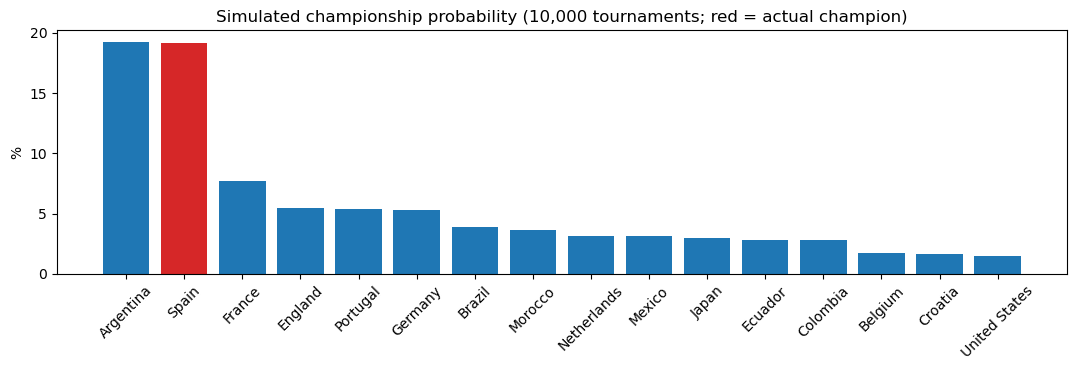

In [37]:
Xwc = F["scaler"].transform(stage4_df.loc[wc["match_id"], F["columns"]]); ywc = wc["y"].to_numpy()
WC_MATCH_METRICS = pd.DataFrame({"frozen ELO model": evaluate(ywc, F["model"].predict_proba(Xwc))[0],
                                 "train class prior": evaluate(ywc, np.tile(TRAIN_PRIOR, (len(ywc), 1)))[0]}).T[["n", "log_loss", "brier", "rps", "accuracy"]]
display(WC_MATCH_METRICS.round(4))

exact = np.concatenate([GROUP_MARGINAL[g][:, 0] for g in GROUPS])
sampled = np.concatenate([MC["group_first"][GROUP_ENUM[g]["team_global"]] / MC["n"] for g in GROUPS])
z = (sampled - exact) / np.sqrt(np.clip(exact * (1 - exact), 1e-12, None) / MC["n"])
coin, other_seed = simulate(shootout="coin"), simulate(seed=MC_SEED + 777)
p_champ = SIMULATION_RESULTS.set_index("Team")["Champion"]
places = {s: 2 * int(((BRACKET["round_idx"] == r) & ~BRACKET["is_third_place"]).sum()) for r, s in ROUND_NAMES.items()} | {"Champion": 1}
check({"stage probabilities never increase from one round to the next": (SIMULATION_RESULTS[REACH_STAGES].diff(axis=1).iloc[:, 1:] <= 1e-12).all().all(),
       "each round's probabilities sum to its number of places": all(abs(SIMULATION_RESULTS[s].sum() - k) < 1e-9 for s, k in places.items()),
       "Round-of-32 entrants are exactly the top two of each group plus the qualifying thirds":
           np.array_equal(MC["counts"]["Round of 32"], MC["top_two"] + MC["qualified_as_third"]),
       f"sampled P(win group) matches the exact enumeration (max |z| = {np.abs(z).max():.2f})": np.abs(z).max() < 4,
       "same seed reproduces the same tournament": np.array_equal(simulate(2000)["counts"]["Champion"], simulate(2000)["counts"]["Champion"])},
      "simulation checks")

actual_reached = {ROUND_NAMES[r]: set(KO.loc[(KO["round_idx"] == r) & ~KO["is_third_place"], ["home_team", "away_team"]].values.ravel()) for r in PLAYING}
actual_reached["Champion"] = {ACTUAL_CHAMPION}
BACKTEST_SUMMARY = pd.DataFrame({s: {"places": len(actual_reached[s]),
    "mean p, teams that got there": SIMULATION_RESULTS.loc[SIMULATION_RESULTS["Team"].isin(actual_reached[s]), s].mean(),
    "mean p, teams that did not": SIMULATION_RESULTS.loc[~SIMULATION_RESULTS["Team"].isin(actual_reached[s]), s].mean(),
    "Brier": np.mean((SIMULATION_RESULTS[s] - SIMULATION_RESULTS["Team"].isin(actual_reached[s])) ** 2)} for s in REACH_STAGES}).T
display(BACKTEST_SUMMARY.round(4))
rank = int(np.flatnonzero(SIMULATION_RESULTS["Team"] == ACTUAL_CHAMPION)[0]) + 1
print(f"Actual champion {ACTUAL_CHAMPION}: simulated P(champion) = {p_champ[ACTUAL_CHAMPION]:.3f}, ranked {rank} of {N_TEAMS} beforehand. "
      f"Largest shift from a coin-flip shootout or a different seed: "
      f"{100 * max(np.abs(coin['counts']['Champion'] / coin['n'] - p_champ[WC_TEAMS].to_numpy()).max(), np.abs(other_seed['counts']['Champion'] / other_seed['n'] - p_champ[WC_TEAMS].to_numpy()).max()):.2f} pp")

fig, ax = plt.subplots(figsize=(11, 3.8))
top = SIMULATION_RESULTS.head(16)
ax.bar(top["Team"], top["Champion"] * 100, color=["C3" if t == ACTUAL_CHAMPION else "C0" for t in top["Team"]])
ax.set(title=f"Simulated championship probability ({N_SIMULATIONS:,} tournaments; red = actual champion)", ylabel="%")
ax.tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()

In [38]:
# ---- 14.5 How much of the tournament answer is noise, and how much is an assumption? -------------
p_ch = SIMULATION_RESULTS.set_index("Team")["Champion"]
mc_se = np.sqrt(p_ch * (1 - p_ch) / N_SIMULATIONS)
sens = pd.DataFrame({"P(champion)": p_ch, "Monte Carlo SE (pp)": 100 * mc_se,
                     "shift: coin-flip shootouts (pp)": 100 * np.abs(pd.Series(coin["counts"]["Champion"] / coin["n"], index=WC_TEAMS)[p_ch.index] - p_ch),
                     "shift: different seed (pp)": 100 * np.abs(pd.Series(other_seed["counts"]["Champion"] / other_seed["n"], index=WC_TEAMS)[p_ch.index] - p_ch)}).head(8)
display(sens.round(2))
print("Read this against the SE column: changing the shootout rule moves the favourites by roughly 2-4 Monte Carlo\n"
      "standard errors, while re-seeding moves them by about 1-2. Neither is large next to the modelling assumptions\n"
      "(frozen ratings, no scoreline), which is the honest statement about where the tournament uncertainty lives.")

conv = pd.DataFrame([{"N": n, "P(champion), favourite": simulate(n, seed=MC_SEED)["counts"]["Champion"][WC_TEAMS.index(p_ch.index[0])] / n,
                      "MC SE (pp)": 100 * np.sqrt(p_ch.iloc[0] * (1 - p_ch.iloc[0]) / n)} for n in [100, 500, 2000, 10000]])
display(conv.set_index("N").round(4))

# Replay: push the REAL group results through the simulator's own ranking rules and see how many teams it places.
real_lvl = {}
for g in GROUPS:
    teams_g = GROUP_TEAMS[g]; tix = {t: i for i, t in enumerate(teams_g)}
    fx = GROUP_MATCHES[GROUP_MATCHES["home_team"].map(TEAM_GROUP) == g]
    pts, h2h = np.zeros(4, int), np.zeros((4, 4), int)
    for h, a, yv in zip(fx["home_team"], fx["away_team"], fx["y"]):
        pts[tix[h]] += PTS_FOR[0][yv]; pts[tix[a]] += PTS_FOR[1][yv]
        h2h[tix[h], tix[a]], h2h[tix[a], tix[h]] = PTS_FOR[0][yv], PTS_FOR[1][yv]
    lvl, _ = rank_levels(pts, h2h)
    for t, l in zip(teams_g, lvl):
        real_lvl[t] = l
placed = sum(int(real_lvl[t]) == int(ACTUAL_SLOT[t][1]) - 1 for t in WC_TEAMS)
print(f"Group-stage replay: points and head-to-head alone place {placed} of {N_TEAMS} teams in the position the real "
      f"tournament gave them; the rest were separated by goal difference, which this model cannot produce (L2).")

# The 104 tournament matches, scored two ways: with in-tournament features, and with the frozen pre-tournament
# states the simulation itself used. The second is the number the tournament probabilities actually rest on.
P_frozen = np.array([(P_HOME if not nz else P_NEUTRAL)[TEAM_IDX[h], TEAM_IDX[a]]
                     for h, a, nz in zip(wc["home_team"], wc["away_team"], wc["neutral"])])
print(f"104 WC matches -- log loss with in-tournament features {log_loss(ywc, F['model'].predict_proba(Xwc)):.4f}; "
      f"with the frozen 2026-06-11 states used by the simulation {log_loss(ywc, P_frozen):.4f}")

check({f"frozen fingerprints unchanged by stages 5 and 6": FINGERPRINTS == {n: fingerprint(f) for n, f in FROZEN.items()}},
      "fingerprint re-check")

,P(champion),Monte Carlo SE (pp),shift: coin-flip shootouts (pp),shift: different seed (pp)
Team,,,,
Argentina,0.19,0.39,1.07,0.03
Spain,0.19,0.39,1.47,0.93
France,0.08,0.27,0.40,0.03
England,0.05,0.23,0.19,0.21
Portugal,0.05,0.23,0.14,0.34
Germany,0.05,0.22,0.31,0.01
Brazil,0.04,0.19,0.13,0.14
Morocco,0.04,0.19,0.09,0.07


Read this against the SE column: changing the shootout rule moves the favourites by roughly 2-4 Monte Carlo
standard errors, while re-seeding moves them by about 1-2. Neither is large next to the modelling assumptions
(frozen ratings, no scoreline), which is the honest statement about where the tournament uncertainty lives.


,"P(champion), favourite",MC SE (pp)
N,,
100,0.2000,3.9426
500,0.1780,1.7632
2000,0.1920,0.8816
10000,0.1925,0.3943


Group-stage replay: points and head-to-head alone place 42 of 48 teams in the position the real tournament gave them; the rest were separated by goal difference, which this model cannot produce (L2).
104 WC matches -- log loss with in-tournament features 0.8454; with the frozen 2026-06-11 states used by the simulation 0.8366
[PASS] frozen fingerprints unchanged by stages 5 and 6


**Limitations.** Team strength is frozen at kickoff (a team that wins three group games is no stronger in the knockouts);
the model outputs no scoreline, so goal difference cannot break group ties (a drawn lot is used instead); the official
third-place allocation table is not in the data, so allocations are drawn at random among valid ones; one real tournament is a
single draw from the distribution, so the backtest can expose gross miscalibration but cannot confirm good calibration.

## 15. Save results and final checkpoint

In [39]:
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
for name, frame in {"elo_k_diagnostics": ELO_K_RESULTS, "incremental_signal": signal, "stage3_results": RESULTS,
                    "regularisation_sweep": sweep, "experiment_results": EXPERIMENT_RESULTS, "all_configurations": ALL_RUNS,
                    "test_results": TEST_RESULTS, "elo_vs_baseline": ELO_COMPARISONS, "calibration": CALIBRATION,
                    "error_analysis_segments": SEGMENTS, "simulation_results": SIMULATION_RESULTS,
                    "simulation_backtest": BACKTEST_SUMMARY, "wc_match_metrics": WC_MATCH_METRICS}.items():
    frame.to_csv(RESULTS_DIR / f"{name}.csv")
(RESULTS_DIR / "run_summary.json").write_text(json.dumps({"best_config": {k: v for k, v in BEST_CONFIG.items() if k != "features"},
                                                          "verdict": VERDICT["verdict"], "seed": SEED, "data_commit": COMMIT}, indent=2, default=str))

check({"test period read only after the models were frozen": TEST_OPEN and all(f["model"].converged_ for f in FROZEN.values()),
       "experiments can only reach train and validation": set(matrices(stage4_df, CONTEXT)[0]) == {"train", "validation"},
       "simulation probabilities come from the frozen ELO model": F is FROZEN["ELO"],
       "results written": len(list(RESULTS_DIR.glob("*.csv"))) >= 13},
      "final checkpoint")
print(f"\nBest configuration: K = {BEST_CONFIG['k']}, N = {BEST_CONFIG['window']}, {BEST_CONFIG['family']}, C = {BEST_CONFIG['C']:g}")
print(f"Test log loss: ELO {TEST_RESULTS.loc['ELO', 'log_loss']:.4f} vs BASE {TEST_RESULTS.loc['BASE', 'log_loss']:.4f} -> {VERDICT['verdict']}")
print(f"Simulated favourite: {SIMULATION_RESULTS['Team'][0]} ({SIMULATION_RESULTS['Champion'][0]:.1%}); actual champion {ACTUAL_CHAMPION} (ranked {rank})")

[PASS] test period read only after the models were frozen
[PASS] experiments can only reach train and validation
[PASS] simulation probabilities come from the frozen ELO model
[PASS] results written

Best configuration: K = 40, N = 10, C basic+Elo+form, C = 0.1
Test log loss: ELO 0.8653 vs BASE 0.9385 -> ELO IMPROVED out-of-sample prediction, by more than sampling noise.
Simulated favourite: Argentina (19.2%); actual champion Spain (ranked 2)
